<a href="https://colab.research.google.com/github/rejaul367/Light-weight-model-for-plant-disease-detection/blob/main/SMG_Lite_Experiments.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SMG_Lite — experiments that fill `result_word.docx`

Every experiment is **one small cell**: one model × one dataset (train → pick best epoch on
validation → test once on the held-out test split). Results are saved in `outputs/`, so

* a finished cell is **skipped** when re-run (set `force=True` in the config to retrain),
* an interrupted cell (Colab / Kaggle time-out) **resumes** from its last epoch,
* the last section **combines** everything into the tables, figures and a filled copy of
  `templates/result_word.docx` → `outputs/result_word_filled.docx`.

### Fast **and** reliable (Google Colab) — do this once
Upload 4 zip files to Google Drive, exactly here:
```
MyDrive/SMG_Lite/
├── SMG_Lite_Experiments.ipynb  ← this notebook (open it from here with Google Colaboratory)
├── SMG_Lite_Project.zip        ← this project folder, zipped
└── datasets/
    ├── plantvillage.zip        ← zip of the class folders
    ├── rice.zip
    └── mango.zip
```
Then open this notebook in Colab (Runtime → GPU) and run from the top. The first cells
1. copy the project and unzip the datasets to Colab's **local disk** → training is **fast**;
2. save every checkpoint and result locally **and copy it to `MyDrive/SMG_Lite/outputs/` after every epoch** → nothing is lost when Colab disconnects;
3. in a new session **restore** everything from Drive → finished cells are skipped, an interrupted cell continues from its last epoch.

On your own PC / Kaggle nothing changes: put the images in `data/<dataset>/` and run.

**Run order:** 0 (setup) → A (Plant Village) → B (Rice) → C (Mango Leaf) → D (Ablation) → E (Combine).
Section A must run before B/C, because B/C start each model from its own Plant Village
checkpoint (`transfer_from="plantvillage"`, applied identically to every model).

| Section | Cells | What it fills in the docx |
|---|---|---|
| A / B / C | 8 models + 2 no-augmentation runs per dataset | the 3 performance tables, metric line chart, training curves, confusion matrix, ROC |
| D | 8 ablation variants (own dataset + own epoch budget) | the ablation table |
| E | combine | `outputs/result_word_filled.docx` + all PNG / CSV files |

> The numbers in the tables are whatever your training runs produce — nothing is typed in by hand.

## 0. Setup

In [ ]:
# 0.1  Where am I?  Colab -> Drive for safety, local disk for speed.  PC / Kaggle -> this folder.
import os, sys, zipfile, subprocess
DRIVE_DIR = "/content/drive/MyDrive/SMG_Lite"   # Colab: folder on Google Drive (see above)
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = "/content/SMG_Lite_Project"     # local disk = fast
    if not os.path.exists(os.path.join(PROJECT_DIR, "smg_lab.py")):
        zipfile.ZipFile(os.path.join(DRIVE_DIR, "SMG_Lite_Project.zip")).extractall("/content")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm", "python-docx"])
else:
    PROJECT_DIR = "."                             # folder that contains SMG_Lite.py and smg_lab.py

os.chdir(PROJECT_DIR); sys.path.insert(0, os.getcwd())
print("project:", os.getcwd(), "| Colab:", IN_COLAB)

Mounted at /content/drive
project: /content/SMG_Lite_Project | Colab: True


In [ ]:
# ------------------------------- CONFIG -------------------------------------
DATASETS = {
    #  key              folder with one sub-folder per class (or train/ val/ test/)   docx title     epochs
    "plantvillage": dict(path="data/plantvillage", title="Plant Village", epochs=30),
    "rice":         dict(path="data/rice",         title="Rice",          epochs=40),
    "cassava":        dict(path="data/cassava",        title="cassava Leaf",    epochs=40),
    "apple":        dict(path="data/apple",        title="apple Leaf",    epochs=40),

}
TABLE_ORDER      = ["plantvillage", "rice","apple", "cassava"]   # order of the 3 tables in result_word.docx

ABLATION_DATASET = "rice"   # ablation uses a different dataset ...
ABLATION_EPOCHS  = 70       # ... and its own epoch budget

QUICK_TEST = False          # True -> 1 epoch x 3 batches per cell, written to outputs_quicktest/

import smg_lab as lab
lab.configure(
    datasets=DATASETS,
    out_dir="outputs_quicktest" if QUICK_TEST else "outputs",
    split=(0.70, 0.15, 0.15),      # train / validation / test (stratified, seed fixed)
    seed=42,
    img_size=224, batch_size=64, workers=4,
    lr=3e-3, wd=5e-2, warmup=3,    # AdamW + warm-up + cosine (train.py)
    mixup=0.2, smooth=0.1, ema_decay=0.999,
    randaug_magnitude=7,
    mixup_off_frac=0.2,            # MixUp/CutMix off for the last 20 % of epochs
    tta=True,                      # flip test-time augmentation, same for every model
    lr_override={"VGG16": 1e-4},   # plain VGG16 (no BatchNorm) diverges at 3e-3 from scratch
    transfer_from="plantvillage",  # Rice / Mango runs start from the same model's Plant Village weights
    ablation_epochs=ABLATION_EPOCHS,
    force=True,
    max_batches=3 if QUICK_TEST else None,
    # Colab: every result + checkpoint is copied to Drive after each epoch, and restored next session
    backup_dir=(os.path.join(DRIVE_DIR, "outputs_quicktest" if QUICK_TEST else "outputs")
                if IN_COLAB else None),
)
# Colab: unzip MyDrive/SMG_Lite/datasets/<name>.zip to the local disk (once per session)
lab.prepare_data(os.path.join(DRIVE_DIR, "datasets") if IN_COLAB else None)
if QUICK_TEST:
    for d in DATASETS.values():
        d["epochs"] = 1
    lab.CFG.update(ablation_epochs=1, warmup=0)
print("device:", lab.DEVICE, "| results ->", lab.CFG["out_dir"])

restored 9 file(s) from backup /content/drive/MyDrive/SMG_Lite/outputs -> outputs
plantvillage  ready  (data/plantvillage)
rice          ready  (data/rice)
cassava       ready  (data/cassava)
apple         ready  (data/apple)
device: cuda | results -> outputs


In [ ]:
# 0.2  Extra baselines: ShuffleNet V2 + EfficientNet-Lite0
import shutil
if IN_COLAB:
    shutil.copy(os.path.join(DRIVE_DIR, "extra_models.py"), ".")   # Drive -> project folder
import extra_models
extra_models.install(lab)

added: ShuffleNetV2, EfficientNet-Lite0 | table order: MobileNetV3-Large, MobileNetV2, VGG16, ResNet50, InceptionV3, Xception, DenseNet121, ShuffleNetV2, EfficientNet-Lite0, SMG_Lite


In [ ]:
# Sanity check: size / compute of every model (38 classes, 224x224) + the data splits
import pandas as pd
rows = []
for m in lab.MODEL_NAMES:
    c = lab.model_cost(lambda nc, m=m: lab.build_model(m, nc), 38)
    rows.append([lab.DISPLAY[m], f"{c['params']:,}", f"{c['size_mb']:.2f}", f"{c['gflops']:.3f}"])
display(pd.DataFrame(rows, columns=["Model", "Trainable parameters", "Size (MB)", "GFLOPs"]))

for name, d in DATASETS.items():
    if os.path.isdir(d["path"]):
        s = lab.get_split(name)
        print(f"{name:13s} classes={len(s['classes']):3d}  train={len(s['train']):6d}  "
              f"val={len(s['val']):5d}  test={len(s['test']):5d}")
    else:
        print(f"{name:13s} -> folder {d['path']} not found (put the dataset there)")

,Model,Trainable parameters,Size (MB),GFLOPs
0,MobileNet V3 Large,"4,250,710",16.22,0.431
1,MobileNet V2,"2,272,550",8.67,0.599
2,Standard VGG16,"134,416,230",512.76,30.933
3,ResNet50,"23,585,894",89.97,8.174
4,InceptionV3,"21,863,430",83.40,5.672
5,Xception,"20,884,814",79.67,9.102
6,DenseNet121,"6,992,806",26.68,5.666
7,SMG_Lite,"2,011,412",7.67,0.426


plantvillage  classes= 39  train= 38812  val= 8318  test= 8318
rice          classes= 10  train=  7284  val= 1561  test= 1562
cassava       classes=  5  train= 14977  val= 3210  test= 3210
apple         classes=  6  train= 12058  val= 2584  test= 2584


## A. Plant Village — table "Performance comparison of various Models on the Plant Village dataset"

In [ ]:
# A1 — MobileNet V3 Large on Plant Village
lab.run("plantvillage", "MobileNetV3-Large")

[plantvillage] MobileNetV3-Large | device=cuda | classes=39 | params=4.252M | epochs=30 | lr=0.003 | aug=True
  ep   1/30  train_loss 2.8913  train_acc  24.35  val_loss 2.1428  val_acc  40.48  best  40.48  126.6s
  ep   2/30  train_loss 2.1351  train_acc  43.40  val_loss 1.0278  val_acc  74.75 (ema)  best  74.75  106.5s
  ep   3/30  train_loss 1.6955  train_acc  56.15  val_loss 0.5004  val_acc  88.60 (ema)  best  88.60  106.9s
  ep   4/30  train_loss 1.4926  train_acc  62.30  val_loss 0.3675  val_acc  93.02 (ema)  best  93.02  106.7s
  ep   5/30  train_loss 1.3806  train_acc  65.80  val_loss 0.3374  val_acc  93.83 (ema)  best  93.83  106.5s
  ep   6/30  train_loss 1.2552  train_acc  69.22  val_loss 0.2990  val_acc  95.14 (ema)  best  95.14  106.7s
  ep   7/30  train_loss 1.1728  train_acc  71.68  val_loss 0.2794  val_acc  95.88 (ema)  best  95.88  106.9s
  ep   8/30  train_loss 1.1614  train_acc  71.71  val_loss 0.2567  val_acc  96.93 (ema)  best  96.93  106.9s
  ep   9/30  train_loss 

{'loss': 0.10972452236280342,
 'accuracy': 99.59124789612888,
 'precision': 99.38067442681117,
 'recall': 99.45146718493902,
 'f1': 99.41372321645822,
 'auc': np.float64(99.99871327578944),
 'kappa': np.float64(99.57191390609398),
 'params': 4251991,
 'trainable': 4251991,
 'size_mb': 16.22005844116211,
 'gflops': 0.43071936,
 'label': '[plantvillage] MobileNetV3-Large',
 'dataset': 'plantvillage',
 'epochs': 30,
 'best_epoch': 30,
 'best_val_acc': 99.69944698244771,
 'aug': True,
 'n_test': 8318,
 'classes': ['Apple___Apple_scab',
  'Apple___Black_rot',
  'Apple___Cedar_apple_rust',
  'Apple___healthy',
  'Background_without_leaves',
  'Blueberry___healthy',
  'Cherry___Powdery_mildew',
  'Cherry___healthy',
  'Corn___Cercospora_leaf_spot Gray_leaf_spot',
  'Corn___Common_rust',
  'Corn___Northern_Leaf_Blight',
  'Corn___healthy',
  'Grape___Black_rot',
  'Grape___Esca_(Black_Measles)',
  'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)',
  'Grape___healthy',
  'Orange___Haunglongbing_(Cit

In [ ]:
# A2 — MobileNet V2 on Plant Village
lab.run("plantvillage", "MobileNetV2")

  resumed at epoch 25/30
[plantvillage] MobileNetV2 | device=cuda | classes=39 | params=2.274M | epochs=30 | lr=0.003 | aug=True
  ep  26/30  train_loss 0.1736  train_acc  98.29  val_loss 0.1363  val_acc  99.47 (ema)  best  99.47  134.1s
  ep  27/30  train_loss 0.1685  train_acc  98.47  val_loss 0.1244  val_acc  99.53 (ema)  best  99.53  106.7s
  ep  28/30  train_loss 0.1641  train_acc  98.65  val_loss 0.1053  val_acc  99.54  best  99.54  107.0s
  ep  29/30  train_loss 0.1628  train_acc  98.54  val_loss 0.1072  val_acc  99.54  best  99.54  106.5s
  ep  30/30  train_loss 0.1613  train_acc  98.66  val_loss 0.1094  val_acc  99.59  best  99.59  107.5s
TEST -> loss 0.1083 | acc 99.53% | prec 99.35% | rec 99.35% | f1 99.35% | auc 100.00% | kappa 99.51% | params 2,273,831 | 8.67 MB | 0.599 GFLOPs


{'loss': 0.10832803334221242,
 'accuracy': 99.53113729261842,
 'precision': 99.3474849045036,
 'recall': 99.34775547685851,
 'f1': 99.34604770455489,
 'auc': np.float64(99.99793441265226),
 'kappa': np.float64(99.50894900855917),
 'params': 2273831,
 'trainable': 2273831,
 'size_mb': 8.67397689819336,
 'gflops': 0.599088384,
 'label': '[plantvillage] MobileNetV2',
 'dataset': 'plantvillage',
 'epochs': 30,
 'best_epoch': 30,
 'best_val_acc': 99.59124789612888,
 'aug': True,
 'n_test': 8318,
 'classes': ['Apple___Apple_scab',
  'Apple___Black_rot',
  'Apple___Cedar_apple_rust',
  'Apple___healthy',
  'Background_without_leaves',
  'Blueberry___healthy',
  'Cherry___Powdery_mildew',
  'Cherry___healthy',
  'Corn___Cercospora_leaf_spot Gray_leaf_spot',
  'Corn___Common_rust',
  'Corn___Northern_Leaf_Blight',
  'Corn___healthy',
  'Grape___Black_rot',
  'Grape___Esca_(Black_Measles)',
  'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)',
  'Grape___healthy',
  'Orange___Haunglongbing_(Citrus_gre

In [ ]:
# A3 — Standard VGG16 on Plant Village
lab.run("plantvillage", "VGG16")

[skip] [plantvillage] VGG16: already done -> loss 0.1346 | acc 99.30% | prec 99.16% | rec 99.14% | f1 99.15% | auc 100.00% | kappa 99.27% | params 134,420,327 | 512.77 MB | 30.933 GFLOPs


{'loss': 0.13462089797873322,
 'accuracy': 99.30271699927867,
 'precision': 99.15973983785248,
 'recall': 99.13614390082006,
 'f1': 99.14581202171043,
 'auc': 99.99693706663652,
 'kappa': 99.26970233487144,
 'params': 134420327,
 'trainable': 134420327,
 'size_mb': 512.7728538513184,
 'gflops': 30.932656128,
 'label': '[plantvillage] VGG16',
 'dataset': 'plantvillage',
 'epochs': 30,
 'best_epoch': 29,
 'best_val_acc': 99.14642943015149,
 'aug': True,
 'n_test': 8318,
 'classes': ['Apple___Apple_scab',
  'Apple___Black_rot',
  'Apple___Cedar_apple_rust',
  'Apple___healthy',
  'Background_without_leaves',
  'Blueberry___healthy',
  'Cherry___Powdery_mildew',
  'Cherry___healthy',
  'Corn___Cercospora_leaf_spot Gray_leaf_spot',
  'Corn___Common_rust',
  'Corn___Northern_Leaf_Blight',
  'Corn___healthy',
  'Grape___Black_rot',
  'Grape___Esca_(Black_Measles)',
  'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)',
  'Grape___healthy',
  'Orange___Haunglongbing_(Citrus_greening)',
  'Peach___Bac

In [ ]:
# A4 — ResNet50 on Plant Village
lab.run("plantvillage", "ResNet50")

[plantvillage] ResNet50 | device=cuda | classes=39 | params=23.588M | epochs=30 | lr=0.003 | aug=True


/content/SMG_Lite_Project/smg_lab.py:500: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step(); ema.update(model)


  ep   1/30  train_loss 2.8062  train_acc  26.60  val_loss 1.3066  val_acc  64.57 (ema)  best  64.57  129.3s
  ep   2/30  train_loss 2.1314  train_acc  43.47  val_loss 0.7816  val_acc  79.38 (ema)  best  79.38  116.6s
  ep   3/30  train_loss 1.7553  train_acc  53.94  val_loss 0.4642  val_acc  88.49 (ema)  best  88.49  116.7s
  ep   4/30  train_loss 1.5384  train_acc  60.64  val_loss 0.3077  val_acc  92.67 (ema)  best  92.67  116.8s
  ep   5/30  train_loss 1.3563  train_acc  65.81  val_loss 0.2385  val_acc  94.87 (ema)  best  94.87  116.5s
  ep   6/30  train_loss 1.2080  train_acc  70.22  val_loss 0.1901  val_acc  96.36 (ema)  best  96.36  116.7s
  ep   7/30  train_loss 1.1696  train_acc  71.39  val_loss 0.1787  val_acc  97.03 (ema)  best  97.03  116.4s
  ep   8/30  train_loss 1.1176  train_acc  73.35  val_loss 0.1670  val_acc  97.32 (ema)  best  97.32  116.7s
  ep   9/30  train_loss 1.1039  train_acc  73.21  val_loss 0.1543  val_acc  97.68 (ema)  best  97.68  117.0s
  ep  10/30  train_

{'loss': 0.10501959395042702,
 'accuracy': 99.68742486174561,
 'precision': 99.55561664642207,
 'recall': 99.5121510239262,
 'f1': 99.53287935871703,
 'auc': np.float64(99.99828057328105),
 'kappa': np.float64(99.67263707270565),
 'params': 23587943,
 'trainable': 23587943,
 'size_mb': 89.98086166381836,
 'gflops': 8.174432256,
 'label': '[plantvillage] ResNet50',
 'dataset': 'plantvillage',
 'epochs': 30,
 'best_epoch': 30,
 'best_val_acc': 99.67540274104351,
 'aug': True,
 'n_test': 8318,
 'classes': ['Apple___Apple_scab',
  'Apple___Black_rot',
  'Apple___Cedar_apple_rust',
  'Apple___healthy',
  'Background_without_leaves',
  'Blueberry___healthy',
  'Cherry___Powdery_mildew',
  'Cherry___healthy',
  'Corn___Cercospora_leaf_spot Gray_leaf_spot',
  'Corn___Common_rust',
  'Corn___Northern_Leaf_Blight',
  'Corn___healthy',
  'Grape___Black_rot',
  'Grape___Esca_(Black_Measles)',
  'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)',
  'Grape___healthy',
  'Orange___Haunglongbing_(Citrus_gre

In [ ]:
# A5 — InceptionV3 on Plant Village
lab.run("plantvillage", "InceptionV3")

[plantvillage] InceptionV3 | device=cuda | classes=39 | params=21.865M | epochs=30 | lr=0.003 | aug=True


/content/SMG_Lite_Project/smg_lab.py:500: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step(); ema.update(model)


  ep   1/30  train_loss 3.8708  train_acc  19.95  val_loss 1.7762  val_acc  54.45 (ema)  best  54.45  125.5s
  ep   2/30  train_loss 2.5710  train_acc  34.93  val_loss 1.1805  val_acc  69.94 (ema)  best  69.94  113.1s
  ep   3/30  train_loss 2.3173  train_acc  39.74  val_loss 1.0813  val_acc  71.62 (ema)  best  71.62  111.9s
  ep   4/30  train_loss 1.9444  train_acc  49.42  val_loss 0.6734  val_acc  83.07 (ema)  best  83.07  113.2s
  ep   5/30  train_loss 1.7241  train_acc  55.47  val_loss 0.4899  val_acc  88.49 (ema)  best  88.49  113.4s
  ep   6/30  train_loss 1.4928  train_acc  61.99  val_loss 0.3751  val_acc  92.44 (ema)  best  92.44  113.2s
  ep   7/30  train_loss 1.3647  train_acc  66.27  val_loss 0.3166  val_acc  94.58 (ema)  best  94.58  112.7s
  ep   8/30  train_loss 1.3220  train_acc  67.21  val_loss 0.3187  val_acc  95.16 (ema)  best  95.16  112.8s
  ep   9/30  train_loss 1.3164  train_acc  67.77  val_loss 0.3160  val_acc  95.08 (ema)  best  95.16  112.4s
  ep  10/30  train_

{'loss': 0.10526180488346776,
 'accuracy': 99.5551815340226,
 'precision': 99.28843289896847,
 'recall': 99.36862323832804,
 'f1': 99.32528565343435,
 'auc': np.float64(99.99813551082836),
 'kappa': np.float64(99.5341369143342),
 'params': 21865479,
 'trainable': 21865479,
 'size_mb': 83.41018295288086,
 'gflops': 5.671905984,
 'label': '[plantvillage] InceptionV3',
 'dataset': 'plantvillage',
 'epochs': 30,
 'best_epoch': 30,
 'best_val_acc': 99.59124789612888,
 'aug': True,
 'n_test': 8318,
 'classes': ['Apple___Apple_scab',
  'Apple___Black_rot',
  'Apple___Cedar_apple_rust',
  'Apple___healthy',
  'Background_without_leaves',
  'Blueberry___healthy',
  'Cherry___Powdery_mildew',
  'Cherry___healthy',
  'Corn___Cercospora_leaf_spot Gray_leaf_spot',
  'Corn___Common_rust',
  'Corn___Northern_Leaf_Blight',
  'Corn___healthy',
  'Grape___Black_rot',
  'Grape___Esca_(Black_Measles)',
  'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)',
  'Grape___healthy',
  'Orange___Haunglongbing_(Citrus_g

In [ ]:
# A6 — Xception on Plant Village
lab.run("plantvillage", "Xception")

[plantvillage] Xception | device=cuda | classes=39 | params=20.887M | epochs=30 | lr=0.003 | aug=True
  ep   1/30  train_loss 2.4446  train_acc  35.62  val_loss 0.6520  val_acc  82.75 (ema)  best  82.75  169.8s
  ep   2/30  train_loss 1.7143  train_acc  55.82  val_loss 0.3161  val_acc  92.50 (ema)  best  92.50  140.4s
  ep   3/30  train_loss 1.3957  train_acc  65.26  val_loss 0.2066  val_acc  95.72 (ema)  best  95.72  140.7s
  ep   4/30  train_loss 1.2549  train_acc  69.84  val_loss 0.1668  val_acc  96.95 (ema)  best  96.95  140.5s
  ep   5/30  train_loss 1.1410  train_acc  72.66  val_loss 0.1475  val_acc  97.76 (ema)  best  97.76  140.7s
  ep   6/30  train_loss 1.0529  train_acc  75.15  val_loss 0.1376  val_acc  98.23 (ema)  best  98.23  140.3s
  ep   7/30  train_loss 1.0636  train_acc  75.10  val_loss 0.1414  val_acc  98.33 (ema)  best  98.33  140.2s
  ep   8/30  train_loss 0.9946  train_acc  76.54  val_loss 0.1423  val_acc  98.62 (ema)  best  98.62  140.1s
  ep   9/30  train_loss 0.

{'loss': 0.10509389730295748,
 'accuracy': 99.7234912238519,
 'precision': 99.54672391283091,
 'recall': 99.53419799280104,
 'f1': 99.54017762894344,
 'auc': np.float64(99.99871398450153),
 'kappa': np.float64(99.7104141585822),
 'params': 20886863,
 'trainable': 20886863,
 'size_mb': 79.67705917358398,
 'gflops': 9.101821888,
 'label': '[plantvillage] Xception',
 'dataset': 'plantvillage',
 'epochs': 30,
 'best_epoch': 30,
 'best_val_acc': 99.74753546525608,
 'aug': True,
 'n_test': 8318,
 'classes': ['Apple___Apple_scab',
  'Apple___Black_rot',
  'Apple___Cedar_apple_rust',
  'Apple___healthy',
  'Background_without_leaves',
  'Blueberry___healthy',
  'Cherry___Powdery_mildew',
  'Cherry___healthy',
  'Corn___Cercospora_leaf_spot Gray_leaf_spot',
  'Corn___Common_rust',
  'Corn___Northern_Leaf_Blight',
  'Corn___healthy',
  'Grape___Black_rot',
  'Grape___Esca_(Black_Measles)',
  'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)',
  'Grape___healthy',
  'Orange___Haunglongbing_(Citrus_gree

In [ ]:
# A7 — DenseNet121 on Plant Village
lab.run("plantvillage", "DenseNet121")

[plantvillage] DenseNet121 | device=cuda | classes=39 | params=6.994M | epochs=30 | lr=0.003 | aug=True
  ep   1/30  train_loss 2.5399  train_acc  33.26  val_loss 1.0431  val_acc  72.47 (ema)  best  72.47  166.6s
  ep   2/30  train_loss 1.9216  train_acc  49.40  val_loss 0.4835  val_acc  88.10 (ema)  best  88.10  139.3s
  ep   3/30  train_loss 1.5696  train_acc  59.52  val_loss 0.2859  val_acc  93.81 (ema)  best  93.81  139.6s
  ep   4/30  train_loss 1.3452  train_acc  66.65  val_loss 0.2121  val_acc  95.95 (ema)  best  95.95  139.7s
  ep   5/30  train_loss 1.2082  train_acc  69.89  val_loss 0.1650  val_acc  97.09 (ema)  best  97.09  139.6s
  ep   6/30  train_loss 1.0705  train_acc  73.94  val_loss 0.1426  val_acc  97.85 (ema)  best  97.85  139.7s
  ep   7/30  train_loss 1.0420  train_acc  75.19  val_loss 0.1358  val_acc  98.30 (ema)  best  98.30  139.4s
  ep   8/30  train_loss 1.0153  train_acc  75.57  val_loss 0.1315  val_acc  98.49 (ema)  best  98.49  139.6s
  ep   9/30  train_loss 

{'loss': 0.10452221212054419,
 'accuracy': 99.7114691031498,
 'precision': 99.52927689897126,
 'recall': 99.45603280514406,
 'f1': 99.49062657355738,
 'auc': np.float64(99.99828896350832),
 'kappa': np.float64(99.69781992954701),
 'params': 6993831,
 'trainable': 6993831,
 'size_mb': 26.67934799194336,
 'gflops': 5.6663552,
 'label': '[plantvillage] DenseNet121',
 'dataset': 'plantvillage',
 'epochs': 30,
 'best_epoch': 27,
 'best_val_acc': 99.7234912238519,
 'aug': True,
 'n_test': 8318,
 'classes': ['Apple___Apple_scab',
  'Apple___Black_rot',
  'Apple___Cedar_apple_rust',
  'Apple___healthy',
  'Background_without_leaves',
  'Blueberry___healthy',
  'Cherry___Powdery_mildew',
  'Cherry___healthy',
  'Corn___Cercospora_leaf_spot Gray_leaf_spot',
  'Corn___Common_rust',
  'Corn___Northern_Leaf_Blight',
  'Corn___healthy',
  'Grape___Black_rot',
  'Grape___Esca_(Black_Measles)',
  'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)',
  'Grape___healthy',
  'Orange___Haunglongbing_(Citrus_green

In [ ]:
# A8 — SMG_Lite (proposed) on Plant Village
lab.run("plantvillage", "SMG_Lite")

[plantvillage] SMG_Lite | device=cuda | classes=39 | params=2.012M | epochs=30 | lr=0.003 | aug=True
  ep   1/30  train_loss 3.0172  train_acc  21.39  val_loss 1.6755  val_acc  54.74 (ema)  best  54.74  169.7s
  ep   2/30  train_loss 2.0504  train_acc  46.49  val_loss 0.6022  val_acc  85.36 (ema)  best  85.36  112.5s
  ep   3/30  train_loss 1.5437  train_acc  60.20  val_loss 0.3400  val_acc  92.91 (ema)  best  92.91  112.9s
  ep   4/30  train_loss 1.3367  train_acc  66.64  val_loss 0.2631  val_acc  95.78 (ema)  best  95.78  112.3s
  ep   5/30  train_loss 1.1798  train_acc  71.15  val_loss 0.2243  val_acc  96.77 (ema)  best  96.77  113.1s
  ep   6/30  train_loss 1.0997  train_acc  73.22  val_loss 0.2095  val_acc  97.70 (ema)  best  97.70  112.8s
  ep   7/30  train_loss 1.0362  train_acc  74.90  val_loss 0.2035  val_acc  98.00 (ema)  best  98.00  112.8s
  ep   8/30  train_loss 0.9792  train_acc  76.53  val_loss 0.1965  val_acc  98.39 (ema)  best  98.39  113.0s
  ep   9/30  train_loss 0.9

{'loss': 0.1111431036519737,
 'accuracy': 99.73551334455398,
 'precision': 99.55607802429856,
 'recall': 99.54384561848329,
 'f1': 99.54414047021794,
 'auc': np.float64(99.99852936807602),
 'kappa': np.float64(99.7230068053569),
 'params': 2012069,
 'trainable': 2012069,
 'size_mb': 7.675434112548828,
 'gflops': 0.426233488,
 'label': '[plantvillage] SMG_Lite',
 'dataset': 'plantvillage',
 'epochs': 30,
 'best_epoch': 29,
 'best_val_acc': 99.78360182736235,
 'aug': True,
 'n_test': 8318,
 'classes': ['Apple___Apple_scab',
  'Apple___Black_rot',
  'Apple___Cedar_apple_rust',
  'Apple___healthy',
  'Background_without_leaves',
  'Blueberry___healthy',
  'Cherry___Powdery_mildew',
  'Cherry___healthy',
  'Corn___Cercospora_leaf_spot Gray_leaf_spot',
  'Corn___Common_rust',
  'Corn___Northern_Leaf_Blight',
  'Corn___healthy',
  'Grape___Black_rot',
  'Grape___Esca_(Black_Measles)',
  'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)',
  'Grape___healthy',
  'Orange___Haunglongbing_(Citrus_greeni

**Plant Village: runs without augmentation** — only needed for the training-curve figure (MobileNetV2 vs proposed, with and without augmentation).

In [ ]:
# A9 — MobileNet V2 on Plant Village, NO augmentation
lab.run("plantvillage", "MobileNetV2", aug=False)

In [ ]:
# A10 — SMG_Lite on Plant Village, NO augmentation
lab.run("plantvillage", "SMG_Lite", aug=False)

## B. Rice — table "Performance comparison of various Models on the Rice dataset"
Each model starts from its own Plant Village checkpoint (section A), then trains on this dataset.

In [ ]:
# B1 — MobileNet V3 Large on Rice
lab.run("rice", "MobileNetV3-Large")

  initialised from outputs/runs/plantvillage/MobileNetV3-Large/best.pt (310/312 tensors; new classifier)
[rice] MobileNetV3-Large | device=cuda | classes=10 | params=4.215M | epochs=40 | lr=0.003 | aug=True
  ep   1/40  train_loss 2.0063  train_acc  30.35  val_loss 1.5750  val_acc  50.22 (ema)  best  50.22   61.5s
  ep   2/40  train_loss 1.6624  train_acc  43.81  val_loss 1.1390  val_acc  66.50 (ema)  best  66.50   29.5s
  ep   3/40  train_loss 1.6091  train_acc  46.50  val_loss 0.9826  val_acc  69.12 (ema)  best  69.12   29.5s
  ep   4/40  train_loss 1.5962  train_acc  47.06  val_loss 0.9081  val_acc  72.01 (ema)  best  72.01   29.5s
  ep   5/40  train_loss 1.4866  train_acc  51.13  val_loss 0.6869  val_acc  78.86 (ema)  best  78.86   29.7s
  ep   6/40  train_loss 1.4105  train_acc  54.14  val_loss 0.6353  val_acc  82.25 (ema)  best  82.25   29.6s
  ep   7/40  train_loss 1.3856  train_acc  55.55  val_loss 0.6175  val_acc  83.73 (ema)  best  83.73   29.7s
  ep   8/40  train_loss 1.3567

{'loss': 0.23180431135081464,
 'accuracy': 97.0550576184379,
 'precision': 97.61595088631448,
 'recall': 96.61973953523214,
 'f1': 97.07469868472401,
 'auc': np.float64(99.80216002809527),
 'kappa': np.float64(96.62436394404259),
 'params': 4214842,
 'trainable': 4214842,
 'size_mb': 16.078346252441406,
 'gflops': 0.43064512,
 'label': '[rice] MobileNetV3-Large',
 'dataset': 'rice',
 'epochs': 40,
 'best_epoch': 36,
 'best_val_acc': 97.11723254324151,
 'aug': True,
 'n_test': 1562,
 'classes': ['bacterial_leaf_blight',
  'bacterial_leaf_streak',
  'bacterial_panicle_blight',
  'blast',
  'brown_spot',
  'dead_heart',
  'downy_mildew',
  'hispa',
  'normal',
  'tungro']}

In [ ]:
# B2 — MobileNet V2 on Rice
lab.run("rice", "MobileNetV2")

  initialised from outputs/runs/plantvillage/MobileNetV2/best.pt (312/314 tensors; new classifier)
[rice] MobileNetV2 | device=cuda | classes=10 | params=2.237M | epochs=40 | lr=0.003 | aug=True
  ep   1/40  train_loss 2.1007  train_acc  25.10  val_loss 1.7114  val_acc  43.63 (ema)  best  43.63   46.1s
  ep   2/40  train_loss 1.7421  train_acc  40.67  val_loss 1.1261  val_acc  65.15 (ema)  best  65.15   30.0s
  ep   3/40  train_loss 1.6988  train_acc  43.66  val_loss 0.9890  val_acc  69.19 (ema)  best  69.19   30.1s
  ep   4/40  train_loss 1.6228  train_acc  45.94  val_loss 0.9015  val_acc  73.80 (ema)  best  73.80   29.9s
  ep   5/40  train_loss 1.5348  train_acc  49.23  val_loss 0.8013  val_acc  76.62 (ema)  best  76.62   29.8s
  ep   6/40  train_loss 1.5254  train_acc  50.23  val_loss 0.7503  val_acc  78.86 (ema)  best  78.86   30.2s
  ep   7/40  train_loss 1.4785  train_acc  51.53  val_loss 0.6987  val_acc  79.50 (ema)  best  79.50   30.0s
  ep   8/40  train_loss 1.4820  train_acc 

{'loss': 0.24905923223712662,
 'accuracy': 94.55825864276568,
 'precision': 93.93808391401826,
 'recall': 93.37933544575642,
 'f1': 93.6175529491438,
 'auc': np.float64(99.63244846128569),
 'kappa': np.float64(93.76277205954892),
 'params': 2236682,
 'trainable': 2236682,
 'size_mb': 8.532264709472656,
 'gflops': 0.599014144,
 'label': '[rice] MobileNetV2',
 'dataset': 'rice',
 'epochs': 40,
 'best_epoch': 39,
 'best_val_acc': 93.85009609224856,
 'aug': True,
 'n_test': 1562,
 'classes': ['bacterial_leaf_blight',
  'bacterial_leaf_streak',
  'bacterial_panicle_blight',
  'blast',
  'brown_spot',
  'dead_heart',
  'downy_mildew',
  'hispa',
  'normal',
  'tungro']}

In [ ]:
# B3 — Standard VGG16 on Rice
lab.run("rice", "VGG16")

  initialised from outputs/runs/plantvillage/VGG16/best.pt (30/32 tensors; new classifier)
[rice] VGG16 | device=cuda | classes=10 | params=134.302M | epochs=40 | lr=0.0001 | aug=True
  ep   1/40  train_loss 2.1503  train_acc  21.34  val_loss 1.8963  val_acc  35.62 (ema)  best  35.62   72.9s
  ep   2/40  train_loss 1.9258  train_acc  33.05  val_loss 1.4744  val_acc  55.41 (ema)  best  55.41   60.7s
  ep   3/40  train_loss 1.8021  train_acc  39.03  val_loss 1.3284  val_acc  59.71 (ema)  best  59.71   65.3s
  ep   4/40  train_loss 1.7641  train_acc  40.36  val_loss 1.2167  val_acc  63.16 (ema)  best  63.16   59.4s
  ep   5/40  train_loss 1.6633  train_acc  44.54  val_loss 1.1043  val_acc  64.96 (ema)  best  64.96   74.4s
  ep   6/40  train_loss 1.6052  train_acc  46.91  val_loss 1.0517  val_acc  67.01 (ema)  best  67.01   61.7s
  ep   7/40  train_loss 1.5703  train_acc  48.72  val_loss 0.9543  val_acc  71.30 (ema)  best  71.30   70.1s
  ep   8/40  train_loss 1.5384  train_acc  49.84  val

{'loss': 0.30926487487307697,
 'accuracy': 92.12548015364916,
 'precision': 91.53976933916631,
 'recall': 90.51957946195166,
 'f1': 90.9973926595508,
 'auc': np.float64(99.45060118401364),
 'kappa': np.float64(90.97453387262708),
 'params': 134301514,
 'trainable': 134301514,
 'size_mb': 512.3196182250977,
 'gflops': 30.93241856,
 'label': '[rice] VGG16',
 'dataset': 'rice',
 'epochs': 40,
 'best_epoch': 37,
 'best_val_acc': 91.22357463164637,
 'aug': True,
 'n_test': 1562,
 'classes': ['bacterial_leaf_blight',
  'bacterial_leaf_streak',
  'bacterial_panicle_blight',
  'blast',
  'brown_spot',
  'dead_heart',
  'downy_mildew',
  'hispa',
  'normal',
  'tungro']}

In [ ]:
# B4 — ResNet50 on Rice
lab.run("rice", "ResNet50")

  initialised from outputs/runs/plantvillage/ResNet50/best.pt (318/320 tensors; new classifier)
[rice] ResNet50 | device=cuda | classes=10 | params=23.529M | epochs=40 | lr=0.003 | aug=True
  ep   1/40  train_loss 2.0610  train_acc  26.72  val_loss 1.5105  val_acc  48.81 (ema)  best  48.81   42.3s
  ep   2/40  train_loss 1.7261  train_acc  40.93  val_loss 1.0629  val_acc  68.55 (ema)  best  68.55   33.2s
  ep   3/40  train_loss 1.6640  train_acc  43.98  val_loss 0.9299  val_acc  71.56 (ema)  best  71.56   33.8s
  ep   4/40  train_loss 1.6162  train_acc  45.69  val_loss 0.8883  val_acc  72.97 (ema)  best  72.97   33.7s
  ep   5/40  train_loss 1.5655  train_acc  48.01  val_loss 0.8205  val_acc  75.27 (ema)  best  75.27   34.0s
  ep   6/40  train_loss 1.5442  train_acc  48.82  val_loss 0.7550  val_acc  79.12 (ema)  best  79.12   37.3s
  ep   7/40  train_loss 1.4706  train_acc  52.25  val_loss 0.6855  val_acc  79.76 (ema)  best  79.76   33.8s
  ep   8/40  train_loss 1.4118  train_acc  54.2

{'loss': 0.22388807242661957,
 'accuracy': 94.94238156209988,
 'precision': 94.16502105185852,
 'recall': 94.27308160452685,
 'f1': 94.16849200205073,
 'auc': np.float64(99.62208946803302),
 'kappa': np.float64(94.20517034915119),
 'params': 23528522,
 'trainable': 23528522,
 'size_mb': 89.75418853759766,
 'gflops': 8.174313472,
 'label': '[rice] ResNet50',
 'dataset': 'rice',
 'epochs': 40,
 'best_epoch': 40,
 'best_val_acc': 95.25944907110826,
 'aug': True,
 'n_test': 1562,
 'classes': ['bacterial_leaf_blight',
  'bacterial_leaf_streak',
  'bacterial_panicle_blight',
  'blast',
  'brown_spot',
  'dead_heart',
  'downy_mildew',
  'hispa',
  'normal',
  'tungro']}

In [ ]:
# B5 — InceptionV3 on Rice
lab.run("rice", "InceptionV3")

  initialised from outputs/runs/plantvillage/InceptionV3/best.pt (564/566 tensors; new classifier)
[rice] InceptionV3 | device=cuda | classes=10 | params=21.806M | epochs=40 | lr=0.003 | aug=True
  ep   1/40  train_loss 2.0329  train_acc  27.88  val_loss 1.2944  val_acc  58.10  best  58.10   44.8s
  ep   2/40  train_loss 1.7299  train_acc  42.06  val_loss 1.0152  val_acc  69.06 (ema)  best  69.06   33.0s
  ep   3/40  train_loss 1.6827  train_acc  44.10  val_loss 0.9416  val_acc  72.52 (ema)  best  72.52   33.0s
  ep   4/40  train_loss 1.6415  train_acc  46.15  val_loss 0.8785  val_acc  75.85 (ema)  best  75.85   33.0s
  ep   5/40  train_loss 1.5643  train_acc  48.91  val_loss 0.7744  val_acc  79.44 (ema)  best  79.44   33.5s
  ep   6/40  train_loss 1.4936  train_acc  51.47  val_loss 0.7237  val_acc  80.33 (ema)  best  80.33   34.7s
  ep   7/40  train_loss 1.5344  train_acc  50.02  val_loss 0.6944  val_acc  82.00 (ema)  best  82.00   36.1s
  ep   8/40  train_loss 1.4319  train_acc  54.2

{'loss': 0.23391282048903056,
 'accuracy': 95.96670934699104,
 'precision': 95.36733782148973,
 'recall': 95.22300726563826,
 'f1': 95.22332302644337,
 'auc': np.float64(99.57917600169766),
 'kappa': np.float64(95.38075686190385),
 'params': 21806058,
 'trainable': 21806058,
 'size_mb': 83.18350982666016,
 'gflops': 5.6717872,
 'label': '[rice] InceptionV3',
 'dataset': 'rice',
 'epochs': 40,
 'best_epoch': 35,
 'best_val_acc': 95.64381806534273,
 'aug': True,
 'n_test': 1562,
 'classes': ['bacterial_leaf_blight',
  'bacterial_leaf_streak',
  'bacterial_panicle_blight',
  'blast',
  'brown_spot',
  'dead_heart',
  'downy_mildew',
  'hispa',
  'normal',
  'tungro']}

In [ ]:
# B6 — Xception on Rice
lab.run("rice", "Xception")

  initialised from outputs/runs/plantvillage/Xception/best.pt (274/276 tensors; new classifier)
  resumed at epoch 4/40
[rice] Xception | device=cuda | classes=10 | params=20.827M | epochs=40 | lr=0.003 | aug=True
  ep   5/40  train_loss 1.3723  train_acc  56.39  val_loss 0.5875  val_acc  83.73 (ema)  best  83.73   33.4s
  ep   6/40  train_loss 1.3021  train_acc  58.67  val_loss 0.5275  val_acc  84.50 (ema)  best  84.50   33.5s
  ep   7/40  train_loss 1.2466  train_acc  60.62  val_loss 0.4946  val_acc  85.59 (ema)  best  85.59   33.0s
  ep   8/40  train_loss 1.2359  train_acc  60.99  val_loss 0.4752  val_acc  86.87 (ema)  best  86.87   33.3s
  ep   9/40  train_loss 1.2661  train_acc  60.29  val_loss 0.4419  val_acc  87.57 (ema)  best  87.57   33.3s
  ep  10/40  train_loss 1.2605  train_acc  61.09  val_loss 0.4318  val_acc  88.66 (ema)  best  88.66   33.4s
  ep  11/40  train_loss 1.2368  train_acc  61.34  val_loss 0.4135  val_acc  89.11 (ema)  best  89.11   34.4s
  ep  12/40  train_loss

{'loss': 0.1754303204416604,
 'accuracy': 96.606914212548,
 'precision': 96.77867417988674,
 'recall': 96.2275228465125,
 'f1': 96.48609748065418,
 'auc': np.float64(99.71515675246133),
 'kappa': np.float64(96.11149861789248),
 'params': 20827442,
 'trainable': 20827442,
 'size_mb': 79.45038604736328,
 'gflops': 9.101703104,
 'label': '[rice] Xception',
 'dataset': 'rice',
 'epochs': 40,
 'best_epoch': 39,
 'best_val_acc': 96.98910954516336,
 'aug': True,
 'n_test': 1562,
 'classes': ['bacterial_leaf_blight',
  'bacterial_leaf_streak',
  'bacterial_panicle_blight',
  'blast',
  'brown_spot',
  'dead_heart',
  'downy_mildew',
  'hispa',
  'normal',
  'tungro']}

In [ ]:
# B7 — DenseNet121 on Rice
lab.run("rice", "DenseNet121")

  initialised from outputs/runs/plantvillage/DenseNet121/best.pt (725/727 tensors; new classifier)
[rice] DenseNet121 | device=cuda | classes=10 | params=6.964M | epochs=40 | lr=0.003 | aug=True
  ep   1/40  train_loss 2.1084  train_acc  25.20  val_loss 1.6072  val_acc  48.81  best  48.81   57.0s
  ep   2/40  train_loss 1.7183  train_acc  42.11  val_loss 1.0612  val_acc  66.62 (ema)  best  66.62   31.3s
  ep   3/40  train_loss 1.5619  train_acc  48.26  val_loss 0.8525  val_acc  72.77 (ema)  best  72.77   31.5s
  ep   4/40  train_loss 1.5545  train_acc  47.89  val_loss 0.8161  val_acc  74.63 (ema)  best  74.63   31.5s
  ep   5/40  train_loss 1.4663  train_acc  52.61  val_loss 0.6840  val_acc  79.12 (ema)  best  79.12   31.4s
  ep   6/40  train_loss 1.3884  train_acc  55.80  val_loss 0.6161  val_acc  82.25 (ema)  best  82.25   31.7s
  ep   7/40  train_loss 1.3525  train_acc  56.60  val_loss 0.5669  val_acc  83.28 (ema)  best  83.28   31.6s
  ep   8/40  train_loss 1.3962  train_acc  54.91

{'loss': 0.17937054149717727,
 'accuracy': 96.79897567221511,
 'precision': 97.12272974545971,
 'recall': 96.20167279236836,
 'f1': 96.61436686739651,
 'auc': np.float64(99.74011389511404),
 'kappa': np.float64(96.33054592643614),
 'params': 6964106,
 'trainable': 6964106,
 'size_mb': 26.565956115722656,
 'gflops': 5.666295808,
 'label': '[rice] DenseNet121',
 'dataset': 'rice',
 'epochs': 40,
 'best_epoch': 36,
 'best_val_acc': 96.47661755285074,
 'aug': True,
 'n_test': 1562,
 'classes': ['bacterial_leaf_blight',
  'bacterial_leaf_streak',
  'bacterial_panicle_blight',
  'blast',
  'brown_spot',
  'dead_heart',
  'downy_mildew',
  'hispa',
  'normal',
  'tungro']}

In [ ]:
# B8 — SMG_Lite (proposed) on Rice
lab.run("rice", "SMG_Lite")

  initialised from outputs/runs/plantvillage/SMG_Lite/best.pt (602/604 tensors; new classifier)
[rice] SMG_Lite | device=cuda | classes=10 | params=1.993M | epochs=40 | lr=0.003 | aug=True
  ep   1/40  train_loss 2.0974  train_acc  29.07  val_loss 1.4360  val_acc  55.54 (ema)  best  55.54   33.0s
  ep   2/40  train_loss 1.5794  train_acc  48.29  val_loss 0.9250  val_acc  72.90 (ema)  best  72.90   29.7s
  ep   3/40  train_loss 1.5267  train_acc  50.15  val_loss 0.7621  val_acc  78.99 (ema)  best  78.99   30.1s
  ep   4/40  train_loss 1.4196  train_acc  54.37  val_loss 0.6391  val_acc  83.02 (ema)  best  83.02   30.2s
  ep   5/40  train_loss 1.2937  train_acc  59.71  val_loss 0.5531  val_acc  85.65 (ema)  best  85.65   30.1s
  ep   6/40  train_loss 1.3139  train_acc  58.94  val_loss 0.5447  val_acc  85.27 (ema)  best  85.65   30.6s
  ep   7/40  train_loss 1.2964  train_acc  58.91  val_loss 0.5062  val_acc  86.93 (ema)  best  86.93   30.0s
  ep   8/40  train_loss 1.2337  train_acc  61.43

{'loss': 0.18154309550944234,
 'accuracy': 97.24711907810499,
 'precision': 97.3674617706781,
 'recall': 96.72980417155067,
 'f1': 97.0095861127477,
 'auc': np.float64(99.71944416087526),
 'kappa': np.float64(96.84469200678171),
 'params': 1993016,
 'trainable': 1993016,
 'size_mb': 7.602752685546875,
 'gflops': 0.42619544,
 'label': '[rice] SMG_Lite',
 'dataset': 'rice',
 'epochs': 40,
 'best_epoch': 35,
 'best_val_acc': 97.62972453555413,
 'aug': True,
 'n_test': 1562,
 'classes': ['bacterial_leaf_blight',
  'bacterial_leaf_streak',
  'bacterial_panicle_blight',
  'blast',
  'brown_spot',
  'dead_heart',
  'downy_mildew',
  'hispa',
  'normal',
  'tungro']}

**Rice: runs without augmentation** — only needed for the training-curve figure (MobileNetV2 vs proposed, with and without augmentation).

In [ ]:
# B9 — MobileNet V2 on Rice, NO augmentation
lab.run("rice", "MobileNetV2", aug=False)

In [ ]:
# B10 — SMG_Lite on Rice, NO augmentation
lab.run("rice", "SMG_Lite", aug=False)

## C. Apple Leaf — table "Performance comparison of various Models on the Apple Leaf dataset"
Each model starts from its own Plant Village checkpoint (section A), then trains on this dataset.

In [ ]:
lab.run("apple", "MobileNetV3-Large")

  initialised from outputs/runs/plantvillage/MobileNetV3-Large/best.pt (310/312 tensors; new classifier)
[apple] MobileNetV3-Large | device=cuda | classes=6 | params=4.210M | epochs=40 | lr=0.003 | aug=True
  ep   1/40  train_loss 1.2307  train_acc  55.51  val_loss 0.5028  val_acc  85.80 (ema)  best  85.80   74.3s
  ep   2/40  train_loss 0.9275  train_acc  69.16  val_loss 0.3898  val_acc  91.45 (ema)  best  91.45   40.7s
  ep   3/40  train_loss 0.9042  train_acc  70.51  val_loss 0.4185  val_acc  89.71 (ema)  best  91.45   40.9s
  ep   4/40  train_loss 0.8855  train_acc  71.23  val_loss 0.4601  val_acc  88.20 (ema)  best  91.45   40.9s
  ep   5/40  train_loss 0.8948  train_acc  70.20  val_loss 0.3381  val_acc  92.69 (ema)  best  92.69   40.9s
  ep   6/40  train_loss 0.8246  train_acc  73.31  val_loss 0.3561  val_acc  92.69 (ema)  best  92.69   40.9s
  ep   7/40  train_loss 0.8688  train_acc  71.48  val_loss 0.3556  val_acc  93.34 (ema)  best  93.34   41.0s
  ep   8/40  train_loss 0.8361

{'loss': 0.20281028585946695,
 'accuracy': 95.89783281733746,
 'precision': 95.32092089144128,
 'recall': 94.37060671333795,
 'f1': 94.77772229174623,
 'auc': np.float64(99.5149715044851),
 'kappa': np.float64(94.80417488599797),
 'params': 4209718,
 'trainable': 4209718,
 'size_mb': 16.058799743652344,
 'gflops': 0.43063488,
 'label': '[apple] MobileNetV3-Large',
 'dataset': 'apple',
 'epochs': 40,
 'best_epoch': 40,
 'best_val_acc': 95.6656346749226,
 'aug': True,
 'n_test': 2584,
 'classes': ['complex',
  'frog_eye_leaf_spot',
  'healthy',
  'powdery_mildew',
  'rust',
  'scab']}

In [ ]:
lab.run("apple", "MobileNetV2")

  initialised from outputs/runs/plantvillage/MobileNetV2/best.pt (312/314 tensors; new classifier)
[apple] MobileNetV2 | device=cuda | classes=6 | params=2.232M | epochs=40 | lr=0.003 | aug=True
  ep   1/40  train_loss 1.3342  train_acc  51.47  val_loss 0.4880  val_acc  86.57 (ema)  best  86.57   57.4s
  ep   2/40  train_loss 0.9428  train_acc  68.88  val_loss 0.3934  val_acc  90.09 (ema)  best  90.09   41.2s
  ep   3/40  train_loss 0.9677  train_acc  67.93  val_loss 0.3816  val_acc  91.25 (ema)  best  91.25   40.8s
  ep   4/40  train_loss 0.9661  train_acc  68.01  val_loss 0.3987  val_acc  90.48 (ema)  best  91.25   40.7s
  ep   5/40  train_loss 0.9560  train_acc  68.08  val_loss 0.3790  val_acc  91.95 (ema)  best  91.95   40.6s
  ep   6/40  train_loss 0.9040  train_acc  70.50  val_loss 0.3601  val_acc  91.80 (ema)  best  91.95   41.1s
  ep   7/40  train_loss 0.8773  train_acc  71.41  val_loss 0.3400  val_acc  92.34 (ema)  best  92.34   40.7s
  ep   8/40  train_loss 0.8361  train_acc 

{'loss': 0.21546162359894014,
 'accuracy': 95.20123839009288,
 'precision': 94.63351737680638,
 'recall': 93.6259250361958,
 'f1': 93.97358146551753,
 'auc': np.float64(99.47312645146077),
 'kappa': np.float64(93.92121806332545),
 'params': 2231558,
 'trainable': 2231558,
 'size_mb': 8.512718200683594,
 'gflops': 0.599003904,
 'label': '[apple] MobileNetV2',
 'dataset': 'apple',
 'epochs': 40,
 'best_epoch': 40,
 'best_val_acc': 95.5108359133127,
 'aug': True,
 'n_test': 2584,
 'classes': ['complex',
  'frog_eye_leaf_spot',
  'healthy',
  'powdery_mildew',
  'rust',
  'scab']}

In [ ]:
lab.run("apple", "VGG16")

  initialised from outputs/runs/plantvillage/VGG16/best.pt (30/32 tensors; new classifier)
[apple] VGG16 | device=cuda | classes=6 | params=134.285M | epochs=40 | lr=0.0001 | aug=True
  ep   1/40  train_loss 1.4398  train_acc  43.01  val_loss 0.6597  val_acc  79.68 (ema)  best  79.68  100.6s
  ep   2/40  train_loss 1.0621  train_acc  64.51  val_loss 0.5170  val_acc  85.64 (ema)  best  85.64   99.6s
  ep   3/40  train_loss 1.0528  train_acc  64.76  val_loss 0.5112  val_acc  86.38 (ema)  best  86.38   86.1s
  ep   4/40  train_loss 0.9625  train_acc  68.53  val_loss 0.4849  val_acc  87.23 (ema)  best  87.23  137.4s
  ep   5/40  train_loss 0.9568  train_acc  68.41  val_loss 0.4446  val_acc  89.67 (ema)  best  89.67   85.2s
  ep   6/40  train_loss 0.9363  train_acc  69.66  val_loss 0.4338  val_acc  89.98  best  89.98   96.1s
  ep   7/40  train_loss 0.9172  train_acc  70.06  val_loss 0.4208  val_acc  90.40 (ema)  best  90.40   95.7s
  ep   8/40  train_loss 0.8994  train_acc  71.08  val_loss 

{'loss': 0.234520533454646,
 'accuracy': 93.92414860681114,
 'precision': 93.3613567068523,
 'recall': 91.61689394244395,
 'f1': 92.20460872295149,
 'auc': np.float64(99.36597065728546),
 'kappa': np.float64(92.29210828758715),
 'params': 134285126,
 'trainable': 134285126,
 'size_mb': 512.2571029663086,
 'gflops': 30.932385792,
 'label': '[apple] VGG16',
 'dataset': 'apple',
 'epochs': 40,
 'best_epoch': 36,
 'best_val_acc': 94.89164086687306,
 'aug': True,
 'n_test': 2584,
 'classes': ['complex',
  'frog_eye_leaf_spot',
  'healthy',
  'powdery_mildew',
  'rust',
  'scab']}

In [ ]:
lab.run("apple", "InceptionV3")

  initialised from outputs/runs/plantvillage/InceptionV3/best.pt (564/566 tensors; new classifier)
[apple] InceptionV3 | device=cuda | classes=6 | params=21.798M | epochs=40 | lr=0.003 | aug=True
  ep   1/40  train_loss 1.3244  train_acc  50.00  val_loss 0.5118  val_acc  86.07 (ema)  best  86.07  122.4s
  ep   2/40  train_loss 0.9577  train_acc  68.90  val_loss 0.4307  val_acc  88.93 (ema)  best  88.93   85.3s
  ep   3/40  train_loss 1.0143  train_acc  66.28  val_loss 0.4406  val_acc  90.02 (ema)  best  90.02  125.3s
  ep   4/40  train_loss 0.9945  train_acc  66.98  val_loss 0.4381  val_acc  90.13 (ema)  best  90.13   83.2s
  ep   5/40  train_loss 0.9432  train_acc  68.72  val_loss 0.4033  val_acc  90.94 (ema)  best  90.94   91.3s
  ep   6/40  train_loss 0.9421  train_acc  69.34  val_loss 0.3972  val_acc  91.83 (ema)  best  91.83  132.8s
  ep   7/40  train_loss 0.9469  train_acc  68.83  val_loss 0.3989  val_acc  91.95 (ema)  best  91.95  141.2s
  ep   8/40  train_loss 0.8877  train_acc

{'loss': 0.22204746329445726,
 'accuracy': 94.73684210526315,
 'precision': 94.1659191317322,
 'recall': 92.88632896545573,
 'f1': 93.33446392562912,
 'auc': np.float64(99.4203792707201),
 'kappa': np.float64(93.32959532731532),
 'params': 21797862,
 'trainable': 21797862,
 'size_mb': 83.1522445678711,
 'gflops': 5.671770816,
 'label': '[apple] InceptionV3',
 'dataset': 'apple',
 'epochs': 40,
 'best_epoch': 33,
 'best_val_acc': 95.12383900928792,
 'aug': True,
 'n_test': 2584,
 'classes': ['complex',
  'frog_eye_leaf_spot',
  'healthy',
  'powdery_mildew',
  'rust',
  'scab']}

In [ ]:
lab.run("apple", "ResNet50")

  initialised from outputs/runs/plantvillage/ResNet50/best.pt (318/320 tensors; new classifier)
[apple] ResNet50 | device=cuda | classes=6 | params=23.520M | epochs=40 | lr=0.003 | aug=True
  ep   1/40  train_loss 1.2750  train_acc  52.92  val_loss 0.4520  val_acc  88.62 (ema)  best  88.62   54.7s
  ep   2/40  train_loss 0.9303  train_acc  68.95  val_loss 0.3539  val_acc  91.02 (ema)  best  91.02   44.9s
  ep   3/40  train_loss 0.9398  train_acc  68.80  val_loss 0.3635  val_acc  90.29 (ema)  best  91.02   44.5s
  ep   4/40  train_loss 0.9819  train_acc  67.30  val_loss 0.3817  val_acc  90.52 (ema)  best  91.02   45.0s
  ep   5/40  train_loss 0.9076  train_acc  69.68  val_loss 0.3446  val_acc  91.72 (ema)  best  91.72   45.0s
  ep   6/40  train_loss 0.9172  train_acc  69.81  val_loss 0.3355  val_acc  92.22 (ema)  best  92.22   45.3s
  ep   7/40  train_loss 0.8775  train_acc  70.87  val_loss 0.3264  val_acc  92.53 (ema)  best  92.53   45.1s
  ep   8/40  train_loss 0.9030  train_acc  70.0

{'loss': 0.19952686957020155,
 'accuracy': 95.08513931888545,
 'precision': 94.31658733614049,
 'recall': 93.61037186126508,
 'f1': 93.89255414228288,
 'auc': np.float64(99.50719058821083),
 'kappa': np.float64(93.77728982320812),
 'params': 23520326,
 'trainable': 23520326,
 'size_mb': 89.7229232788086,
 'gflops': 8.174297088,
 'label': '[apple] ResNet50',
 'dataset': 'apple',
 'epochs': 40,
 'best_epoch': 37,
 'best_val_acc': 95.70433436532507,
 'aug': True,
 'n_test': 2584,
 'classes': ['complex',
  'frog_eye_leaf_spot',
  'healthy',
  'powdery_mildew',
  'rust',
  'scab']}

In [ ]:
lab.run("apple", "Xception")

  initialised from outputs/runs/plantvillage/Xception/best.pt (274/276 tensors; new classifier)
[apple] Xception | device=cuda | classes=6 | params=20.819M | epochs=40 | lr=0.003 | aug=True
  ep   1/40  train_loss 1.2663  train_acc  54.78  val_loss 0.4625  val_acc  87.65 (ema)  best  87.65   82.0s
  ep   2/40  train_loss 0.8924  train_acc  70.55  val_loss 0.3584  val_acc  92.18 (ema)  best  92.18   47.4s
  ep   3/40  train_loss 0.8885  train_acc  70.81  val_loss 0.3414  val_acc  92.84 (ema)  best  92.84   48.1s
  ep   4/40  train_loss 0.9026  train_acc  70.35  val_loss 0.3359  val_acc  93.07 (ema)  best  93.07   47.3s
  ep   5/40  train_loss 0.8310  train_acc  73.37  val_loss 0.3064  val_acc  93.69 (ema)  best  93.69   47.6s
  ep   6/40  train_loss 0.8825  train_acc  71.42  val_loss 0.3279  val_acc  93.81 (ema)  best  93.81   47.5s
  ep   7/40  train_loss 0.8091  train_acc  73.69  val_loss 0.3006  val_acc  93.61 (ema)  best  93.81   47.1s
  ep   8/40  train_loss 0.8509  train_acc  72.2

{'loss': 0.1871008752256003,
 'accuracy': 95.97523219814241,
 'precision': 95.77654284817066,
 'recall': 94.45809205991247,
 'f1': 94.97600770095961,
 'auc': np.float64(99.54517638518821),
 'kappa': np.float64(94.89983319925128),
 'params': 20819246,
 'trainable': 20819246,
 'size_mb': 79.41912078857422,
 'gflops': 9.10168672,
 'label': '[apple] Xception',
 'dataset': 'apple',
 'epochs': 40,
 'best_epoch': 38,
 'best_val_acc': 95.89783281733746,
 'aug': True,
 'n_test': 2584,
 'classes': ['complex',
  'frog_eye_leaf_spot',
  'healthy',
  'powdery_mildew',
  'rust',
  'scab']}

In [ ]:
lab.run("apple", "DenseNet121")

  initialised from outputs/runs/plantvillage/DenseNet121/best.pt (725/727 tensors; new classifier)
[apple] DenseNet121 | device=cuda | classes=6 | params=6.960M | epochs=40 | lr=0.003 | aug=True
  ep   1/40  train_loss 1.3706  train_acc  49.02  val_loss 0.4782  val_acc  87.93 (ema)  best  87.93   74.3s
  ep   2/40  train_loss 0.8920  train_acc  71.08  val_loss 0.3557  val_acc  91.72 (ema)  best  91.72   46.0s
  ep   3/40  train_loss 0.8897  train_acc  70.74  val_loss 0.3172  val_acc  92.45 (ema)  best  92.45   46.1s
  ep   4/40  train_loss 0.8896  train_acc  70.65  val_loss 0.3165  val_acc  92.38 (ema)  best  92.45   46.3s
  ep   5/40  train_loss 0.8859  train_acc  70.66  val_loss 0.3306  val_acc  91.60 (ema)  best  92.45   45.8s
  ep   6/40  train_loss 0.8502  train_acc  72.66  val_loss 0.3095  val_acc  93.03 (ema)  best  93.03   46.1s
  ep   7/40  train_loss 0.8483  train_acc  71.99  val_loss 0.3033  val_acc  93.11 (ema)  best  93.11   46.0s
  ep   8/40  train_loss 0.8651  train_acc 

{'loss': 0.22511776557369226,
 'accuracy': 95.54953560371517,
 'precision': 95.03395309348443,
 'recall': 93.65831049394366,
 'f1': 94.14066484354603,
 'auc': np.float64(99.51989409889399),
 'kappa': np.float64(94.35979197509775),
 'params': 6960006,
 'trainable': 6960006,
 'size_mb': 26.550315856933594,
 'gflops': 5.666287616,
 'label': '[apple] DenseNet121',
 'dataset': 'apple',
 'epochs': 40,
 'best_epoch': 35,
 'best_val_acc': 95.62693498452013,
 'aug': True,
 'n_test': 2584,
 'classes': ['complex',
  'frog_eye_leaf_spot',
  'healthy',
  'powdery_mildew',
  'rust',
  'scab']}

In [ ]:
lab.run("apple", "SMG_Lite")

  initialised from outputs/runs/plantvillage/SMG_Lite/best.pt (602/604 tensors; new classifier)
[apple] SMG_Lite | device=cuda | classes=6 | params=1.990M | epochs=40 | lr=0.003 | aug=True
  ep   1/40  train_loss 1.3419  train_acc  54.22  val_loss 0.4716  val_acc  89.47  best  89.47   85.5s
  ep   2/40  train_loss 0.8635  train_acc  71.96  val_loss 0.3764  val_acc  91.49 (ema)  best  91.49   42.1s
  ep   3/40  train_loss 0.9021  train_acc  70.08  val_loss 0.3801  val_acc  92.34 (ema)  best  92.34   41.4s
  ep   4/40  train_loss 0.8854  train_acc  70.64  val_loss 0.3634  val_acc  93.11 (ema)  best  93.11   41.6s
  ep   5/40  train_loss 0.8292  train_acc  72.88  val_loss 0.3444  val_acc  93.46 (ema)  best  93.46   41.5s
  ep   6/40  train_loss 0.8441  train_acc  72.61  val_loss 0.3484  val_acc  93.54 (ema)  best  93.54   42.0s
  ep   7/40  train_loss 0.7983  train_acc  74.37  val_loss 0.3360  val_acc  93.42 (ema)  best  93.54   42.2s
  ep   8/40  train_loss 0.8092  train_acc  73.78  val_

{'loss': 0.22209904807368272,
 'accuracy': 96.01393188854489,
 'precision': 95.55559943870689,
 'recall': 94.4127149100133,
 'f1': 94.82132351660954,
 'auc': np.float64(99.59111406242405),
 'kappa': np.float64(94.950125871175),
 'params': 1990388,
 'trainable': 1990388,
 'size_mb': 7.5927276611328125,
 'gflops': 0.426190192,
 'label': '[apple] SMG_Lite',
 'dataset': 'apple',
 'epochs': 40,
 'best_epoch': 36,
 'best_val_acc': 96.20743034055728,
 'aug': True,
 'n_test': 2584,
 'classes': ['complex',
  'frog_eye_leaf_spot',
  'healthy',
  'powdery_mildew',
  'rust',
  'scab']}

## C. Cassava Leaf — table "Performance comparison of various Models on the Cassava Leaf dataset"
Each model starts from its own Plant Village checkpoint (section A), then trains on this dataset.

In [ ]:
# C1 — MobileNet V3 Large on Mango Leaf
lab.run("cassava", "MobileNetV3-Large")

  initialised from outputs/runs/plantvillage/MobileNetV3-Large/best.pt (310/312 tensors; new classifier)
[cassava] MobileNetV3-Large | device=cuda | classes=5 | params=4.208M | epochs=40 | lr=0.003 | aug=True
  ep   1/40  train_loss 1.0997  train_acc  60.65  val_loss 0.7129  val_acc  73.80 (ema)  best  73.80  105.9s
  ep   2/40  train_loss 0.9056  train_acc  68.01  val_loss 0.6202  val_acc  78.57 (ema)  best  78.57   73.1s
  ep   3/40  train_loss 0.8842  train_acc  69.07  val_loss 0.5817  val_acc  80.37 (ema)  best  80.37   72.9s
  ep   4/40  train_loss 0.8904  train_acc  68.88  val_loss 0.5687  val_acc  80.69 (ema)  best  80.69   72.8s
  ep   5/40  train_loss 0.8505  train_acc  70.52  val_loss 0.5667  val_acc  81.99 (ema)  best  81.99   73.0s
  ep   6/40  train_loss 0.8368  train_acc  70.84  val_loss 0.5421  val_acc  83.05 (ema)  best  83.05   72.9s
  ep   7/40  train_loss 0.8375  train_acc  71.12  val_loss 0.5370  val_acc  83.74 (ema)  best  83.74   72.6s
  ep   8/40  train_loss 0.83

{'loss': 0.45752606306075866,
 'accuracy': 85.98130841121495,
 'precision': 77.30630891489567,
 'recall': 74.06739012481735,
 'f1': 75.197715618913,
 'auc': np.float64(95.86059694724668),
 'kappa': np.float64(75.55942604158807),
 'params': 4208437,
 'trainable': 4208437,
 'size_mb': 16.053913116455078,
 'gflops': 0.43063232,
 'label': '[cassava] MobileNetV3-Large',
 'dataset': 'cassava',
 'epochs': 40,
 'best_epoch': 35,
 'best_val_acc': 87.601246105919,
 'aug': True,
 'n_test': 3210,
 'classes': ['Cassava_Bacterial_Blight_CBB',
  'Cassava_Brown_Streak_Disease_CBSD',
  'Cassava_Green_Mottle_CGM',
  'Cassava_Mosaic_Disease_CMD',
  'Healthy']}

In [ ]:
# C2 — MobileNet V2 on Mango Leaf
lab.run("cassava", "MobileNetV2")

  initialised from outputs/runs/plantvillage/MobileNetV2/best.pt (312/314 tensors; new classifier)
[cassava] MobileNetV2 | device=cuda | classes=5 | params=2.230M | epochs=40 | lr=0.003 | aug=True
  ep   1/40  train_loss 1.1367  train_acc  60.69  val_loss 0.7911  val_acc  73.30 (ema)  best  73.30   97.8s
  ep   2/40  train_loss 0.9079  train_acc  67.68  val_loss 0.6200  val_acc  79.60 (ema)  best  79.60   72.8s
  ep   3/40  train_loss 0.8877  train_acc  68.89  val_loss 0.6108  val_acc  80.50 (ema)  best  80.50   73.0s
  ep   4/40  train_loss 0.8977  train_acc  68.62  val_loss 0.6067  val_acc  80.44 (ema)  best  80.50   73.1s


KeyboardInterrupt: 

In [ ]:
# C3 — Standard VGG16 on Mango Leaf
lab.run("mango", "VGG16")

In [ ]:
# C4 — ResNet50 on Mango Leaf
lab.run("mango", "ResNet50")

In [ ]:
# C5 — InceptionV3 on Mango Leaf
lab.run("mango", "InceptionV3")

In [ ]:
# C6 — Xception on Mango Leaf
lab.run("cassava", "Xception")

  initialised from outputs/runs/plantvillage/Xception/best.pt (274/276 tensors; new classifier)
[cassava] Xception | device=cuda | classes=5 | params=20.817M | epochs=40 | lr=0.003 | aug=True


Exception ignored in atexit callback <function _exit_function at 0x7f29a1885760>:
Traceback (most recent call last):
  File "/usr/lib/python3.13/multiprocessing/util.py", line 431, in _exit_function
    _run_finalizers()
  File "/usr/lib/python3.13/multiprocessing/util.py", line 371, in _run_finalizers
    finalizer()
  File "/usr/lib/python3.13/multiprocessing/util.py", line 295, in __call__
    res = self._callback(*self._args, **self._kwargs)
  File "/usr/lib/python3.13/multiprocessing/util.py", line 147, in _remove_temp_dir
    rmtree(tempdir)
  File "/usr/lib/python3.13/shutil.py", line 763, in rmtree
    _rmtree_safe_fd(stack, onexc)
  File "/usr/lib/python3.13/shutil.py", line 665, in _rmtree_safe_fd
    orig_st = os.lstat(name, dir_fd=dirfd)
KeyboardInterrupt: 


KeyboardInterrupt: 

In [ ]:
# C7 — DenseNet121 on Mango Leaf
lab.run("mango", "DenseNet121")

In [ ]:
# C8 — SMG_Lite (proposed) on Mango Leaf
lab.run("cassava", "SMG_Lite")

  initialised from outputs/runs/plantvillage/SMG_Lite/best.pt (602/604 tensors; new classifier)
[cassava] SMG_Lite | device=cuda | classes=5 | params=1.990M | epochs=40 | lr=0.003 | aug=True
  ep   1/40  train_loss 1.2214  train_acc  57.18  val_loss 0.7389  val_acc  75.61 (ema)  best  75.61  117.4s
  ep   2/40  train_loss 0.8834  train_acc  68.94  val_loss 0.6230  val_acc  79.94 (ema)  best  79.94   73.2s
  ep   3/40  train_loss 0.8616  train_acc  69.39  val_loss 0.5760  val_acc  81.99 (ema)  best  81.99   73.7s
  ep   4/40  train_loss 0.8622  train_acc  70.29  val_loss 0.5738  val_acc  82.55 (ema)  best  82.55   73.5s
  ep   5/40  train_loss 0.8454  train_acc  70.31  val_loss 0.5562  val_acc  82.93 (ema)  best  82.93   73.4s
  ep   6/40  train_loss 0.8166  train_acc  71.66  val_loss 0.5387  val_acc  83.08 (ema)  best  83.08   73.0s
  ep   7/40  train_loss 0.8096  train_acc  71.81  val_loss 0.5242  val_acc  84.02 (ema)  best  84.02   73.5s
  ep   8/40  train_loss 0.8070  train_acc  71.

{'loss': 0.45348127805705274,
 'accuracy': 85.79439252336448,
 'precision': 76.2822158946109,
 'recall': 73.44338362575988,
 'f1': 74.38553854919509,
 'auc': np.float64(95.876009399006),
 'kappa': np.float64(75.21407191028055),
 'params': 1989731,
 'trainable': 1989731,
 'size_mb': 7.590221405029297,
 'gflops': 0.42618888,
 'label': '[cassava] SMG_Lite',
 'dataset': 'cassava',
 'epochs': 40,
 'best_epoch': 36,
 'best_val_acc': 87.57009345794393,
 'aug': True,
 'n_test': 3210,
 'classes': ['Cassava_Bacterial_Blight_CBB',
  'Cassava_Brown_Streak_Disease_CBSD',
  'Cassava_Green_Mottle_CGM',
  'Cassava_Mosaic_Disease_CMD',
  'Healthy']}

**Mango Leaf: runs without augmentation** — only needed for the training-curve figure (MobileNetV2 vs proposed, with and without augmentation).

In [ ]:
# C9 — MobileNet V2 on Mango Leaf, NO augmentation
lab.run("mango", "MobileNetV2", aug=False)

In [ ]:
# C10 — SMG_Lite on Mango Leaf, NO augmentation
lab.run("mango", "SMG_Lite", aug=False)

## D. Ablation studies on SMG_Lite

Runs on `ABLATION_DATASET` with `ABLATION_EPOCHS` (set in the config), every variant from scratch.
`SMG_Lite.py` is not edited — components are switched off when the model is built:

* **Ghost ✗** → ordinary 1×1 expansion conv instead of the Ghost expansion
* **MS-DW gate ✗** → a single depthwise 3×3 instead of the gated 3×3 + 5×5 multi-scale depthwise
* **CEA ✗** → the Coordinate-ECA attention is removed (identity)

To run the ablation on another dataset as well, change `ABLATION_DATASET` and run these 8 cells again;
section E then builds one ablation table per dataset.

In [ ]:
# D1 — Ghost ✗ | MS-DW gate ✗ | CEA ✗
lab.run_ablation(ABLATION_DATASET, ghost=False, msdw=False, cea=False)

[ablation rice] Ghost=False MS-DW gate=False CEA=False | device=cuda | classes=10 | params=1.093M | epochs=70 | lr=0.003 | aug=True
  ep   1/70  train_loss 2.1958  train_acc  17.63  val_loss 2.0801  val_acc  25.94  best  25.94   31.7s
  ep   2/70  train_loss 2.1277  train_acc  21.58  val_loss 1.9289  val_acc  32.29 (ema)  best  32.29   30.4s
  ep   3/70  train_loss 2.0554  train_acc  26.27  val_loss 1.8311  val_acc  36.13 (ema)  best  36.13   30.4s
  ep   4/70  train_loss 2.0165  train_acc  28.65  val_loss 1.7804  val_acc  39.72  best  39.72   30.4s
  ep   5/70  train_loss 1.9866  train_acc  30.02  val_loss 1.7093  val_acc  41.45 (ema)  best  41.45   30.6s
  ep   6/70  train_loss 1.9750  train_acc  31.15  val_loss 1.6555  val_acc  43.75 (ema)  best  43.75   29.7s
  ep   7/70  train_loss 1.9425  train_acc  32.76  val_loss 1.6187  val_acc  45.74 (ema)  best  45.74   30.1s
  ep   8/70  train_loss 1.9072  train_acc  33.85  val_loss 1.5560  val_acc  47.85 (ema)  best  47.85   30.5s
  ep   9

{'loss': 0.4427917742772464,
 'accuracy': 87.77208706786172,
 'precision': 87.0286156881372,
 'recall': 84.5622290025909,
 'f1': 85.59991005684128,
 'auc': np.float64(98.71335750476548),
 'kappa': np.float64(85.96819466236224),
 'params': 1092906,
 'trainable': 1092906,
 'size_mb': 4.169105529785156,
 'gflops': 0.446585792,
 'label': '[ablation rice] Ghost=False MS-DW gate=False CEA=False',
 'dataset': 'rice',
 'epochs': 70,
 'best_epoch': 69,
 'best_val_acc': 87.31582319026265,
 'aug': True,
 'n_test': 1562,
 'classes': ['bacterial_leaf_blight',
  'bacterial_leaf_streak',
  'bacterial_panicle_blight',
  'blast',
  'brown_spot',
  'dead_heart',
  'downy_mildew',
  'hispa',
  'normal',
  'tungro']}

In [ ]:
# D2 — Ghost ✓ | MS-DW gate ✗ | CEA ✗
lab.run_ablation(ABLATION_DATASET, ghost=True, msdw=False, cea=False)

[ablation rice] Ghost=True MS-DW gate=False CEA=False | device=cuda | classes=10 | params=0.888M | epochs=70 | lr=0.003 | aug=True
  ep   1/70  train_loss 2.1951  train_acc  17.20  val_loss 2.1855  val_acc  25.62  best  25.62   30.3s
  ep   2/70  train_loss 2.1197  train_acc  21.88  val_loss 1.8882  val_acc  33.82 (ema)  best  33.82   29.6s
  ep   3/70  train_loss 2.0485  train_acc  25.92  val_loss 1.8063  val_acc  36.13 (ema)  best  36.13   29.6s
  ep   4/70  train_loss 2.0096  train_acc  28.81  val_loss 1.7560  val_acc  39.97 (ema)  best  39.97   29.2s
  ep   5/70  train_loss 1.9891  train_acc  30.26  val_loss 1.6907  val_acc  42.60 (ema)  best  42.60   29.4s
  ep   6/70  train_loss 1.9364  train_acc  32.41  val_loss 1.6102  val_acc  46.76 (ema)  best  46.76   29.5s
  ep   7/70  train_loss 1.9112  train_acc  33.63  val_loss 1.5417  val_acc  48.75 (ema)  best  48.75   29.6s
  ep   8/70  train_loss 1.8680  train_acc  36.01  val_loss 1.4993  val_acc  51.12 (ema)  best  51.12   29.6s
  e

{'loss': 0.3719670713634505,
 'accuracy': 90.14084507042254,
 'precision': 90.08000537757533,
 'recall': 88.01553248898347,
 'f1': 88.91447102325193,
 'auc': np.float64(99.13969925962043),
 'kappa': np.float64(88.69426751592357),
 'params': 888070,
 'trainable': 888070,
 'size_mb': 3.3877182006835938,
 'gflops': 0.3529072,
 'label': '[ablation rice] Ghost=True MS-DW gate=False CEA=False',
 'dataset': 'rice',
 'epochs': 70,
 'best_epoch': 69,
 'best_val_acc': 90.51889814221653,
 'aug': True,
 'n_test': 1562,
 'classes': ['bacterial_leaf_blight',
  'bacterial_leaf_streak',
  'bacterial_panicle_blight',
  'blast',
  'brown_spot',
  'dead_heart',
  'downy_mildew',
  'hispa',
  'normal',
  'tungro']}

In [ ]:
# D3 — Ghost ✗ | MS-DW gate ✓ | CEA ✗
lab.run_ablation(ABLATION_DATASET, ghost=False, msdw=True, cea=False)

[ablation rice] Ghost=False MS-DW gate=True CEA=False | device=cuda | classes=10 | params=1.864M | epochs=70 | lr=0.003 | aug=True
  ep   1/70  train_loss 2.2029  train_acc  17.44  val_loss 2.0091  val_acc  28.57 (ema)  best  28.57   29.9s
  ep   2/70  train_loss 2.0779  train_acc  26.34  val_loss 1.8827  val_acc  32.86 (ema)  best  32.86   29.9s
  ep   3/70  train_loss 2.0247  train_acc  28.47  val_loss 1.8309  val_acc  41.38  best  41.38   30.1s
  ep   4/70  train_loss 2.0055  train_acc  29.30  val_loss 1.7687  val_acc  43.95  best  43.95   29.7s
  ep   5/70  train_loss 1.9656  train_acc  31.52  val_loss 1.6228  val_acc  45.04 (ema)  best  45.04   29.8s
  ep   6/70  train_loss 1.9349  train_acc  33.21  val_loss 1.5786  val_acc  46.44 (ema)  best  46.44   29.5s
  ep   7/70  train_loss 1.8902  train_acc  34.67  val_loss 1.5224  val_acc  50.35 (ema)  best  50.35   29.5s
  ep   8/70  train_loss 1.8561  train_acc  36.67  val_loss 1.4747  val_acc  52.40 (ema)  best  52.40   29.5s
  ep   9/

{'loss': 0.24798846837870572,
 'accuracy': 94.1101152368758,
 'precision': 93.32320362943904,
 'recall': 92.83769321297632,
 'f1': 92.9990530501833,
 'auc': np.float64(99.65202175091561),
 'kappa': np.float64(93.25018658933485),
 'params': 1863960,
 'trainable': 1863960,
 'size_mb': 7.110443115234375,
 'gflops': 0.510776784,
 'label': '[ablation rice] Ghost=False MS-DW gate=True CEA=False',
 'dataset': 'rice',
 'epochs': 70,
 'best_epoch': 68,
 'best_val_acc': 95.1953875720692,
 'aug': True,
 'n_test': 1562,
 'classes': ['bacterial_leaf_blight',
  'bacterial_leaf_streak',
  'bacterial_panicle_blight',
  'blast',
  'brown_spot',
  'dead_heart',
  'downy_mildew',
  'hispa',
  'normal',
  'tungro']}

In [ ]:
# D4 — Ghost ✗ | MS-DW gate ✗ | CEA ✓
lab.run_ablation(ABLATION_DATASET, ghost=False, msdw=False, cea=True)

[ablation rice] Ghost=False MS-DW gate=False CEA=True | device=cuda | classes=10 | params=1.427M | epochs=70 | lr=0.003 | aug=True
  ep   1/70  train_loss 2.1931  train_acc  17.38  val_loss 2.0540  val_acc  27.99 (ema)  best  27.99   29.5s
  ep   2/70  train_loss 2.0977  train_acc  23.38  val_loss 1.8037  val_acc  36.52 (ema)  best  36.52   29.3s
  ep   3/70  train_loss 2.0175  train_acc  28.87  val_loss 1.7207  val_acc  40.55 (ema)  best  40.55   29.3s
  ep   4/70  train_loss 1.9797  train_acc  30.71  val_loss 1.7046  val_acc  45.68  best  45.68   29.1s
  ep   5/70  train_loss 1.9327  train_acc  32.80  val_loss 1.5822  val_acc  48.56  best  48.56   29.4s
  ep   6/70  train_loss 1.9140  train_acc  33.41  val_loss 1.5031  val_acc  50.10 (ema)  best  50.10   29.2s
  ep   7/70  train_loss 1.8647  train_acc  35.86  val_loss 1.4845  val_acc  51.76 (ema)  best  51.76   29.2s
  ep   8/70  train_loss 1.8496  train_acc  37.00  val_loss 1.4220  val_acc  54.52 (ema)  best  54.52   29.5s
  ep   9/

{'loss': 0.26429991909115547,
 'accuracy': 94.1101152368758,
 'precision': 94.13492745143891,
 'recall': 92.9883962166504,
 'f1': 93.4494316510914,
 'auc': np.float64(99.3838266303116),
 'kappa': np.float64(93.24675764100819),
 'params': 1426798,
 'trainable': 1426798,
 'size_mb': 5.442802429199219,
 'gflops': 0.45568304,
 'label': '[ablation rice] Ghost=False MS-DW gate=False CEA=True',
 'dataset': 'rice',
 'epochs': 70,
 'best_epoch': 63,
 'best_val_acc': 94.74695707879565,
 'aug': True,
 'n_test': 1562,
 'classes': ['bacterial_leaf_blight',
  'bacterial_leaf_streak',
  'bacterial_panicle_blight',
  'blast',
  'brown_spot',
  'dead_heart',
  'downy_mildew',
  'hispa',
  'normal',
  'tungro']}

In [ ]:
# D5 — Ghost ✓ | MS-DW gate ✓ | CEA ✗
lab.run_ablation(ABLATION_DATASET, ghost=True, msdw=True, cea=False)

[ablation rice] Ghost=True MS-DW gate=True CEA=False | device=cuda | classes=10 | params=1.659M | epochs=70 | lr=0.003 | aug=True
  ep   1/70  train_loss 2.2033  train_acc  17.64  val_loss 2.0887  val_acc  25.18 (ema)  best  25.18   29.9s
  ep   2/70  train_loss 2.1320  train_acc  21.56  val_loss 2.0336  val_acc  31.58  best  31.58   29.9s
  ep   3/70  train_loss 2.0691  train_acc  26.10  val_loss 1.7987  val_acc  36.64 (ema)  best  36.64   29.7s
  ep   4/70  train_loss 1.9862  train_acc  30.21  val_loss 1.7338  val_acc  40.81 (ema)  best  40.81   29.7s
  ep   5/70  train_loss 1.9418  train_acc  31.84  val_loss 1.6661  val_acc  43.75 (ema)  best  43.75   29.9s
  ep   6/70  train_loss 1.9001  train_acc  34.72  val_loss 1.5596  val_acc  47.79  best  47.79   29.4s
  ep   7/70  train_loss 1.9046  train_acc  34.40  val_loss 1.4988  val_acc  50.86 (ema)  best  50.86   29.6s
  ep   8/70  train_loss 1.8330  train_acc  37.03  val_loss 1.4220  val_acc  54.77 (ema)  best  54.77   29.9s
  ep   9/7

{'loss': 0.23727504149924214,
 'accuracy': 94.81434058898847,
 'precision': 95.06276697361675,
 'recall': 93.3659664664402,
 'f1': 94.1173826732061,
 'auc': np.float64(99.63552206378813),
 'kappa': np.float64(94.0527739807804),
 'params': 1659124,
 'trainable': 1659124,
 'size_mb': 6.3290557861328125,
 'gflops': 0.417098192,
 'label': '[ablation rice] Ghost=True MS-DW gate=True CEA=False',
 'dataset': 'rice',
 'epochs': 70,
 'best_epoch': 59,
 'best_val_acc': 95.45163356822549,
 'aug': True,
 'n_test': 1562,
 'classes': ['bacterial_leaf_blight',
  'bacterial_leaf_streak',
  'bacterial_panicle_blight',
  'blast',
  'brown_spot',
  'dead_heart',
  'downy_mildew',
  'hispa',
  'normal',
  'tungro']}

In [ ]:
# D6 — Ghost ✓ | MS-DW gate ✗ | CEA ✓
lab.run_ablation(ABLATION_DATASET, ghost=True, msdw=False, cea=True)

[ablation rice] Ghost=True MS-DW gate=False CEA=True | device=cuda | classes=10 | params=1.222M | epochs=70 | lr=0.003 | aug=True
  ep   1/70  train_loss 2.2020  train_acc  17.97  val_loss 2.1611  val_acc  29.34  best  29.34   30.1s
  ep   2/70  train_loss 2.0939  train_acc  24.17  val_loss 1.8806  val_acc  34.72 (ema)  best  34.72   29.6s
  ep   3/70  train_loss 2.0110  train_acc  29.20  val_loss 1.7583  val_acc  39.14 (ema)  best  39.14   29.7s
  ep   4/70  train_loss 1.9817  train_acc  30.56  val_loss 1.6894  val_acc  44.46  best  44.46   29.5s
  ep   5/70  train_loss 1.9350  train_acc  32.96  val_loss 1.6976  val_acc  44.46  best  44.46   29.6s
  ep   6/70  train_loss 1.9066  train_acc  33.76  val_loss 1.5758  val_acc  48.24  best  48.24   29.5s
  ep   7/70  train_loss 1.8862  train_acc  35.46  val_loss 1.5230  val_acc  48.69 (ema)  best  48.69   29.4s
  ep   8/70  train_loss 1.8599  train_acc  36.58  val_loss 1.5226  val_acc  50.67  best  50.67   29.6s
  ep   9/70  train_loss 1.86

{'loss': 0.22354283816748907,
 'accuracy': 94.87836107554418,
 'precision': 94.46718154551348,
 'recall': 93.9280202184864,
 'f1': 94.1014064766447,
 'auc': np.float64(99.55188460747794),
 'kappa': np.float64(94.1318483879254),
 'params': 1221962,
 'trainable': 1221962,
 'size_mb': 4.661415100097656,
 'gflops': 0.362004448,
 'label': '[ablation rice] Ghost=True MS-DW gate=False CEA=True',
 'dataset': 'rice',
 'epochs': 70,
 'best_epoch': 69,
 'best_val_acc': 94.74695707879565,
 'aug': True,
 'n_test': 1562,
 'classes': ['bacterial_leaf_blight',
  'bacterial_leaf_streak',
  'bacterial_panicle_blight',
  'blast',
  'brown_spot',
  'dead_heart',
  'downy_mildew',
  'hispa',
  'normal',
  'tungro']}

In [ ]:
# D7 — Ghost ✗ | MS-DW gate ✓ | CEA ✓
lab.run_ablation(ABLATION_DATASET, ghost=False, msdw=True, cea=True)

[ablation rice] Ghost=False MS-DW gate=True CEA=True | device=cuda | classes=10 | params=2.198M | epochs=70 | lr=0.003 | aug=True
  ep   1/70  train_loss 2.2229  train_acc  16.21  val_loss 2.0873  val_acc  24.28  best  24.28   30.2s
  ep   2/70  train_loss 2.1368  train_acc  20.33  val_loss 2.0245  val_acc  29.79  best  29.79   29.7s
  ep   3/70  train_loss 2.0814  train_acc  24.27  val_loss 1.8662  val_acc  33.57 (ema)  best  33.57   29.7s
  ep   4/70  train_loss 2.0426  train_acc  27.12  val_loss 1.8167  val_acc  37.16 (ema)  best  37.16   29.6s
  ep   5/70  train_loss 1.9938  train_acc  29.67  val_loss 1.7594  val_acc  42.54  best  42.54   29.7s
  ep   6/70  train_loss 1.9452  train_acc  32.40  val_loss 1.6799  val_acc  44.39 (ema)  best  44.39   29.6s
  ep   7/70  train_loss 1.9364  train_acc  32.81  val_loss 1.5678  val_acc  47.41  best  47.41   29.8s
  ep   8/70  train_loss 1.9014  train_acc  34.46  val_loss 1.5557  val_acc  48.88  best  48.88   29.8s
  ep   9/70  train_loss 1.90

{'loss': 0.21377537152607243,
 'accuracy': 96.03072983354673,
 'precision': 96.57918267290071,
 'recall': 95.23454983387121,
 'f1': 95.84191469056694,
 'auc': np.float64(99.7238914284219),
 'kappa': np.float64(95.4489318307847),
 'params': 2197852,
 'trainable': 2197852,
 'size_mb': 8.384140014648438,
 'gflops': 0.519874032,
 'label': '[ablation rice] Ghost=False MS-DW gate=True CEA=True',
 'dataset': 'rice',
 'epochs': 70,
 'best_epoch': 68,
 'best_val_acc': 96.09224855861626,
 'aug': True,
 'n_test': 1562,
 'classes': ['bacterial_leaf_blight',
  'bacterial_leaf_streak',
  'bacterial_panicle_blight',
  'blast',
  'brown_spot',
  'dead_heart',
  'downy_mildew',
  'hispa',
  'normal',
  'tungro']}

In [ ]:
# D8 — Ghost ✓ | MS-DW gate ✓ | CEA ✓
lab.run_ablation(ABLATION_DATASET, ghost=True, msdw=True, cea=True)

[ablation rice] Ghost=True MS-DW gate=True CEA=True | device=cuda | classes=10 | params=1.993M | epochs=70 | lr=0.003 | aug=True
  ep   1/70  train_loss 2.2402  train_acc  16.16  val_loss 2.1818  val_acc  18.96  best  18.96   30.6s
  ep   2/70  train_loss 2.1431  train_acc  20.12  val_loss 2.0392  val_acc  26.52 (ema)  best  26.52   30.2s
  ep   3/70  train_loss 2.1083  train_acc  21.29  val_loss 2.4683  val_acc  32.48  best  32.48   30.6s
  ep   4/70  train_loss 2.0712  train_acc  24.86  val_loss 1.8603  val_acc  36.13 (ema)  best  36.13   30.2s
  ep   5/70  train_loss 2.0023  train_acc  28.87  val_loss 1.7766  val_acc  40.10  best  40.10   29.9s
  ep   6/70  train_loss 1.9658  train_acc  31.39  val_loss 1.6708  val_acc  44.20  best  44.20   30.4s
  ep   7/70  train_loss 1.9443  train_acc  32.27  val_loss 1.6429  val_acc  44.65 (ema)  best  44.65   29.9s
  ep   8/70  train_loss 1.9170  train_acc  34.14  val_loss 1.5901  val_acc  47.28 (ema)  best  47.28   29.9s
  ep   9/70  train_loss

{'loss': 0.21515197001473116,
 'accuracy': 96.22279129321383,
 'precision': 95.95515909100524,
 'recall': 95.52047061840231,
 'f1': 95.7111191027742,
 'auc': np.float64(99.6443580885636),
 'kappa': np.float64(95.67137020827286),
 'params': 1993016,
 'trainable': 1993016,
 'size_mb': 7.602752685546875,
 'gflops': 0.42619544,
 'label': '[ablation rice] Ghost=True MS-DW gate=True CEA=True',
 'dataset': 'rice',
 'epochs': 70,
 'best_epoch': 67,
 'best_val_acc': 96.22037155669443,
 'aug': True,
 'n_test': 1562,
 'classes': ['bacterial_leaf_blight',
  'bacterial_leaf_streak',
  'bacterial_panicle_blight',
  'blast',
  'brown_spot',
  'dead_heart',
  'downy_mildew',
  'hispa',
  'normal',
  'tungro']}

In [ ]:
# D8 — Ghost ✓ | MS-DW gate ✓ | CEA ✓
lab.run_ablation(ABLATION_DATASET, ghost=True, msdw=True, cea=True)

## E. Combine → tables, figures and `result_word_filled.docx`

In [ ]:
ablation_sets = [d for d in DATASETS
                 if os.path.isdir(os.path.join(lab.CFG["out_dir"], "ablation", d))] or [ABLATION_DATASET]
report = lab.make_report(TABLE_ORDER, ablation_sets, template="templates/result_word.docx")

### Performance comparison of various Models on the Plant Village dataset

,Model,Model Size (in MB),Total Trainable parameters,Loss,Accuracy,Precision,Recall,F1-score,AUC- Score,Kappa Score,GFLOPS
0,MobileNet V3 Large,16.22,"4,251,991",0.1097,99.59 %,99.38 %,99.45 %,99.41 %,100.00 %,99.57 %,0.431
1,MobileNet V2,8.67,"2,273,831",0.1083,99.53 %,99.35 %,99.35 %,99.35 %,100.00 %,99.51 %,0.599
2,Standard VGG16,512.77,"134,420,327",0.1346,99.30 %,99.16 %,99.14 %,99.15 %,100.00 %,99.27 %,30.933
3,ResNet50,89.98,"23,587,943",0.1050,99.69 %,99.56 %,99.51 %,99.53 %,100.00 %,99.67 %,8.174
4,InceptionV3,83.41,"21,865,479",0.1053,99.56 %,99.29 %,99.37 %,99.33 %,100.00 %,99.53 %,5.672
5,Xception,79.68,"20,886,863",0.1051,99.72 %,99.55 %,99.53 %,99.54 %,100.00 %,99.71 %,9.102
6,DenseNet121,26.68,"6,993,831",0.1045,99.71 %,99.53 %,99.46 %,99.49 %,100.00 %,99.70 %,5.666
7,SMG_Lite,7.68,"2,012,069",0.1111,99.74 %,99.56 %,99.54 %,99.54 %,100.00 %,99.72 %,0.426


### Performance comparison of various Models on the Rice dataset

,Model,Model Size (in MB),Total Trainable parameters,Loss,Accuracy,Precision,Recall,F1-score,AUC- Score,Kappa Score,GFLOPS
0,MobileNet V3 Large,16.08,"4,214,842",0.2318,97.06 %,97.62 %,96.62 %,97.07 %,99.80 %,96.62 %,0.431
1,MobileNet V2,8.53,"2,236,682",0.2491,94.56 %,93.94 %,93.38 %,93.62 %,99.63 %,93.76 %,0.599
2,Standard VGG16,512.32,"134,301,514",0.3093,92.13 %,91.54 %,90.52 %,91.00 %,99.45 %,90.97 %,30.932
3,ResNet50,89.75,"23,528,522",0.2239,94.94 %,94.17 %,94.27 %,94.17 %,99.62 %,94.21 %,8.174
4,InceptionV3,83.18,"21,806,058",0.2339,95.97 %,95.37 %,95.22 %,95.22 %,99.58 %,95.38 %,5.672
5,Xception,79.45,"20,827,442",0.1754,96.61 %,96.78 %,96.23 %,96.49 %,99.72 %,96.11 %,9.102
6,DenseNet121,26.57,"6,964,106",0.1794,96.80 %,97.12 %,96.20 %,96.61 %,99.74 %,96.33 %,5.666
7,SMG_Lite,7.60,"1,993,016",0.1815,97.25 %,97.37 %,96.73 %,97.01 %,99.72 %,96.84 %,0.426


### Performance comparison of various Models on the apple Leaf dataset

...

### Performance comparison of various Models on the cassava Leaf dataset

,Model,Model Size (in MB),Total Trainable parameters,Loss,Accuracy,Precision,Recall,F1-score,AUC- Score,Kappa Score,GFLOPS
0,MobileNet V3 Large,16.05,"4,208,437",0.4575,85.98 %,77.31 %,74.07 %,75.20 %,95.86 %,75.56 %,0.431
1,MobileNet V2,,,,,,,,,,
2,Standard VGG16,,,,,,,,,,
3,ResNet50,,,,,,,,,,
4,InceptionV3,,,,,,,,,,
5,Xception,,,,,,,,,,
6,DenseNet121,,,,,,,,,,
7,SMG_Lite,7.59,"1,989,731",0.4535,85.79 %,76.28 %,73.44 %,74.39 %,95.88 %,75.21 %,0.426


### Ablation studies on proposed model (Rice)

,Ghost,MS-DW gate,CEA,Model Size,Total parameters,Loss,Accuracy,Precision,Recall,F1-score,AUC-Score,Kappa Score
0,–,–,–,4.17,"1,092,906",0.4428,87.77 %,87.03 %,84.56 %,85.60 %,98.71 %,85.97 %
1,✓,–,–,3.39,"888,070",0.3720,90.14 %,90.08 %,88.02 %,88.91 %,99.14 %,88.69 %
2,–,✓,–,7.11,"1,863,960",0.2480,94.11 %,93.32 %,92.84 %,93.00 %,99.65 %,93.25 %
3,–,–,✓,5.44,"1,426,798",0.2643,94.11 %,94.13 %,92.99 %,93.45 %,99.38 %,93.25 %
4,✓,✓,–,6.33,"1,659,124",0.2373,94.81 %,95.06 %,93.37 %,94.12 %,99.64 %,94.05 %
5,✓,–,✓,4.66,"1,221,962",0.2235,94.88 %,94.47 %,93.93 %,94.10 %,99.55 %,94.13 %
6,–,✓,✓,8.38,"2,197,852",0.2138,96.03 %,96.58 %,95.23 %,95.84 %,99.72 %,95.45 %
7,✓,✓,✓,7.60,"1,993,016",0.2152,96.22 %,95.96 %,95.52 %,95.71 %,99.64 %,95.67 %



Word report written -> outputs/result_word_filled.docx
Tables (csv/png)    -> outputs/tables
Figures (png)       -> outputs/figures
Everything is also saved in /content/drive/MyDrive/SMG_Lite/outputs


outputs/figures/metrics_lines_plantvillage.png


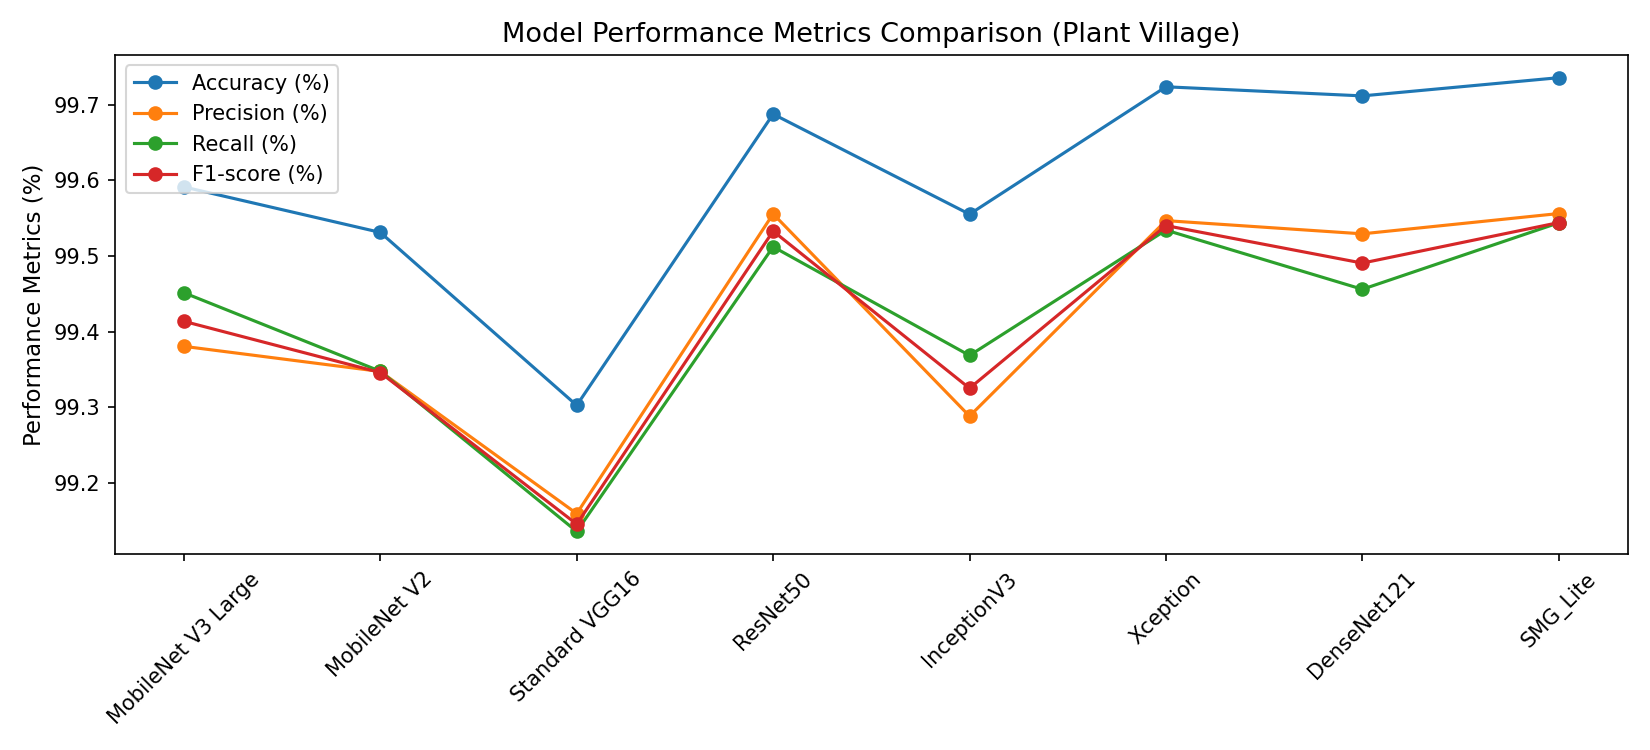

outputs/figures/metrics_lines_rice.png


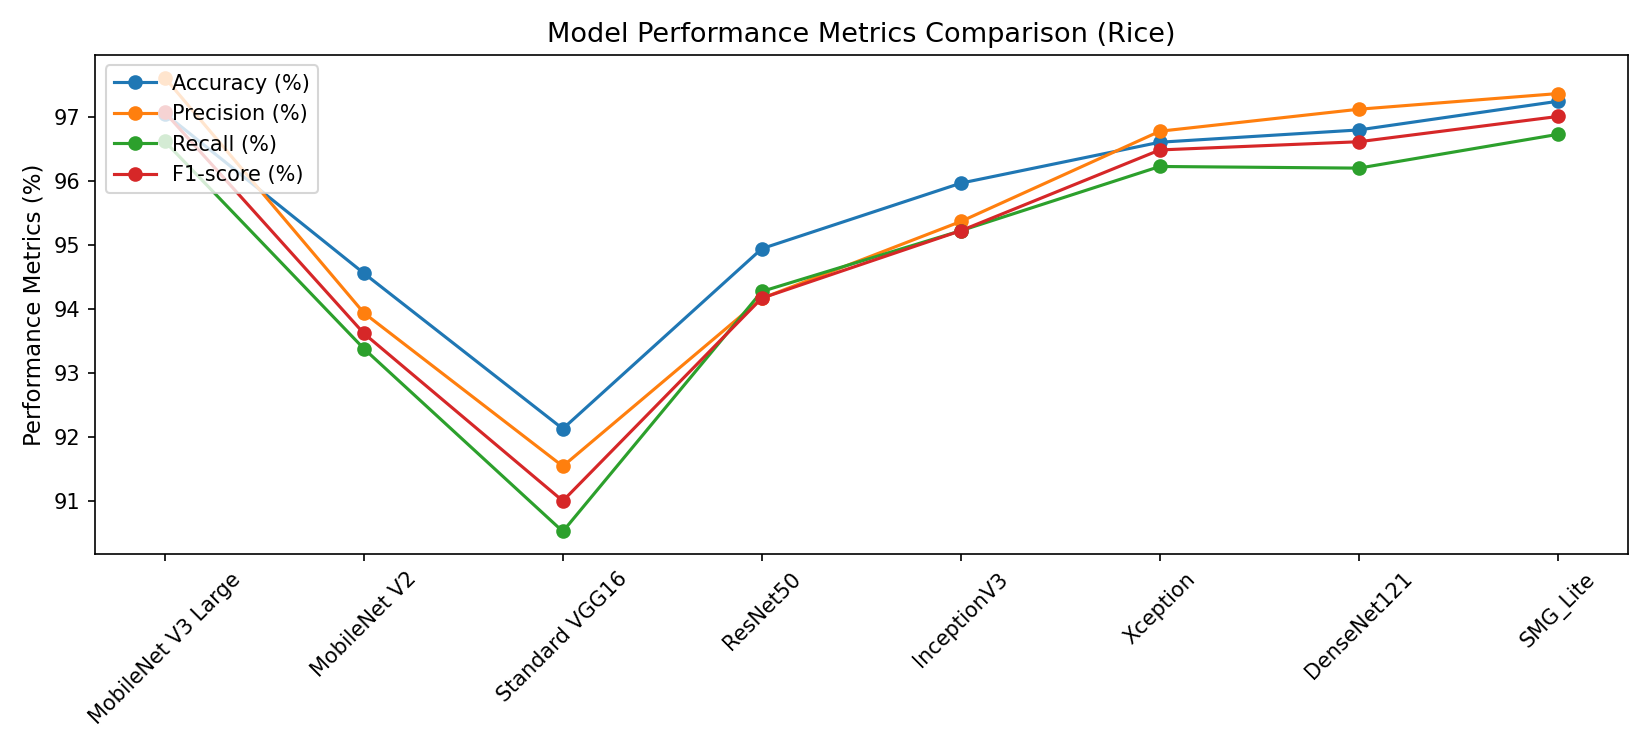

outputs/figures/metrics_lines_apple.png


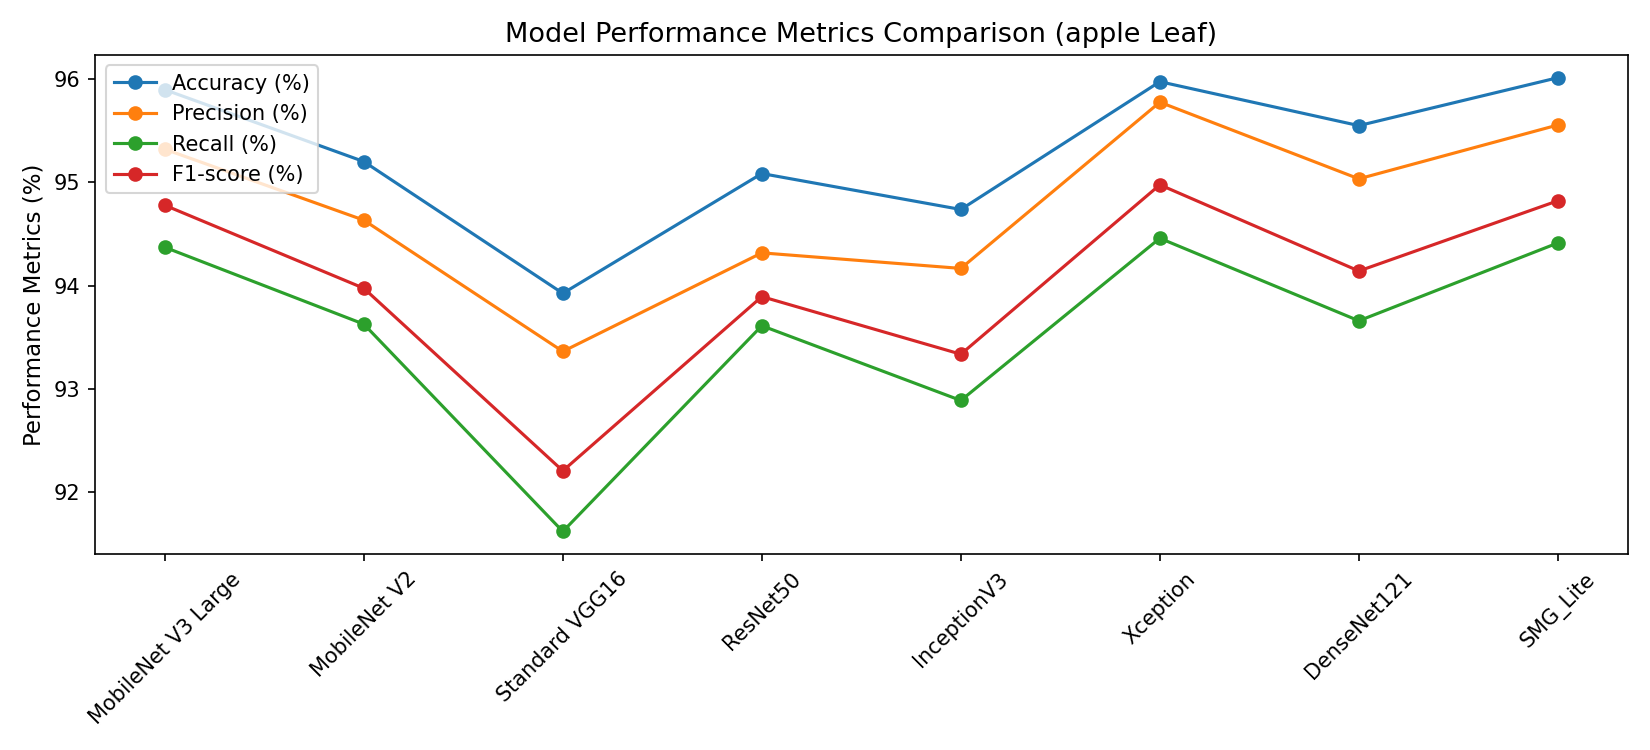

outputs/figures/metrics_lines_cassava.png


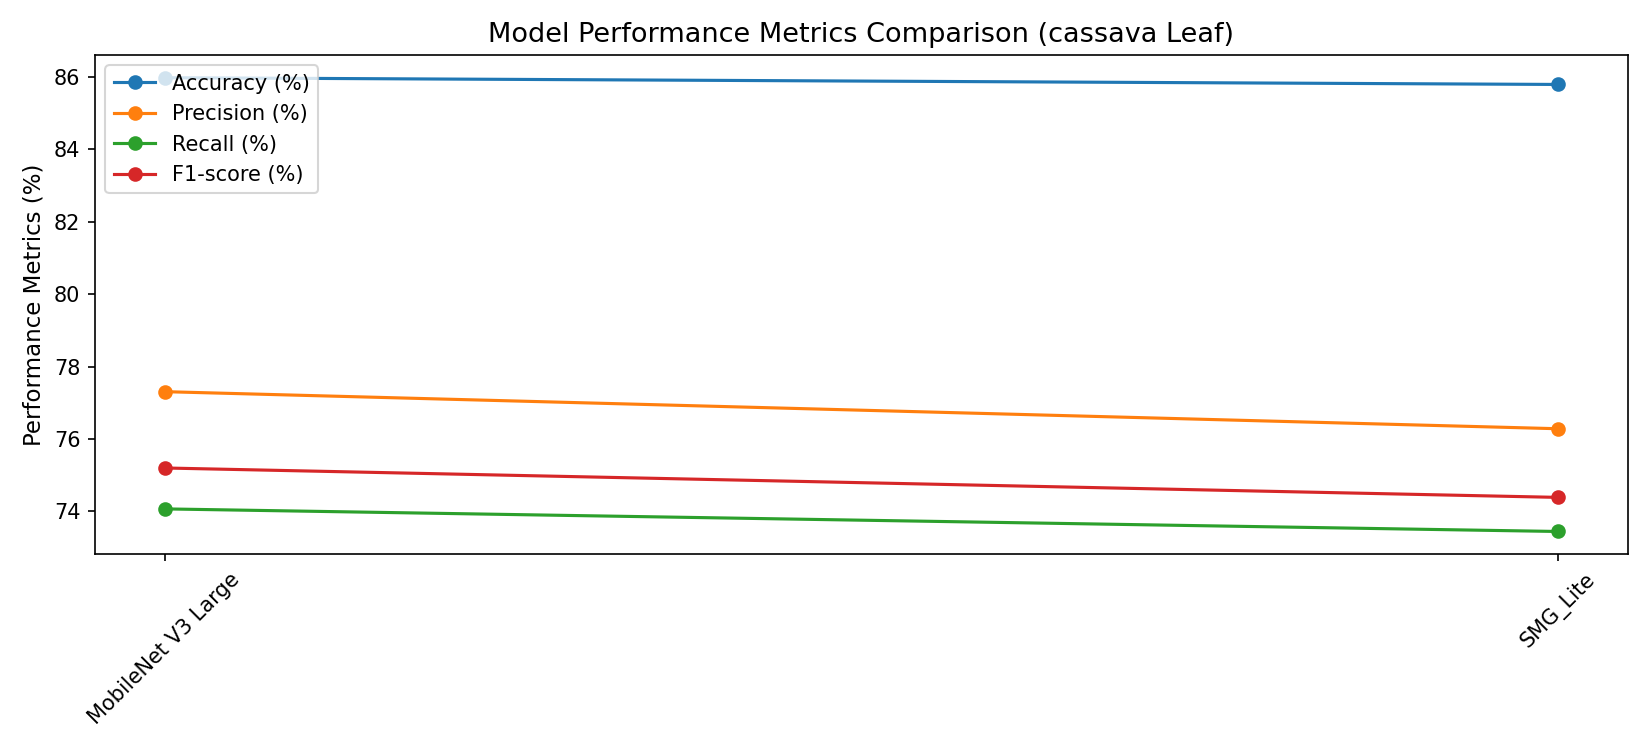

outputs/figures/curves_plantvillage.png


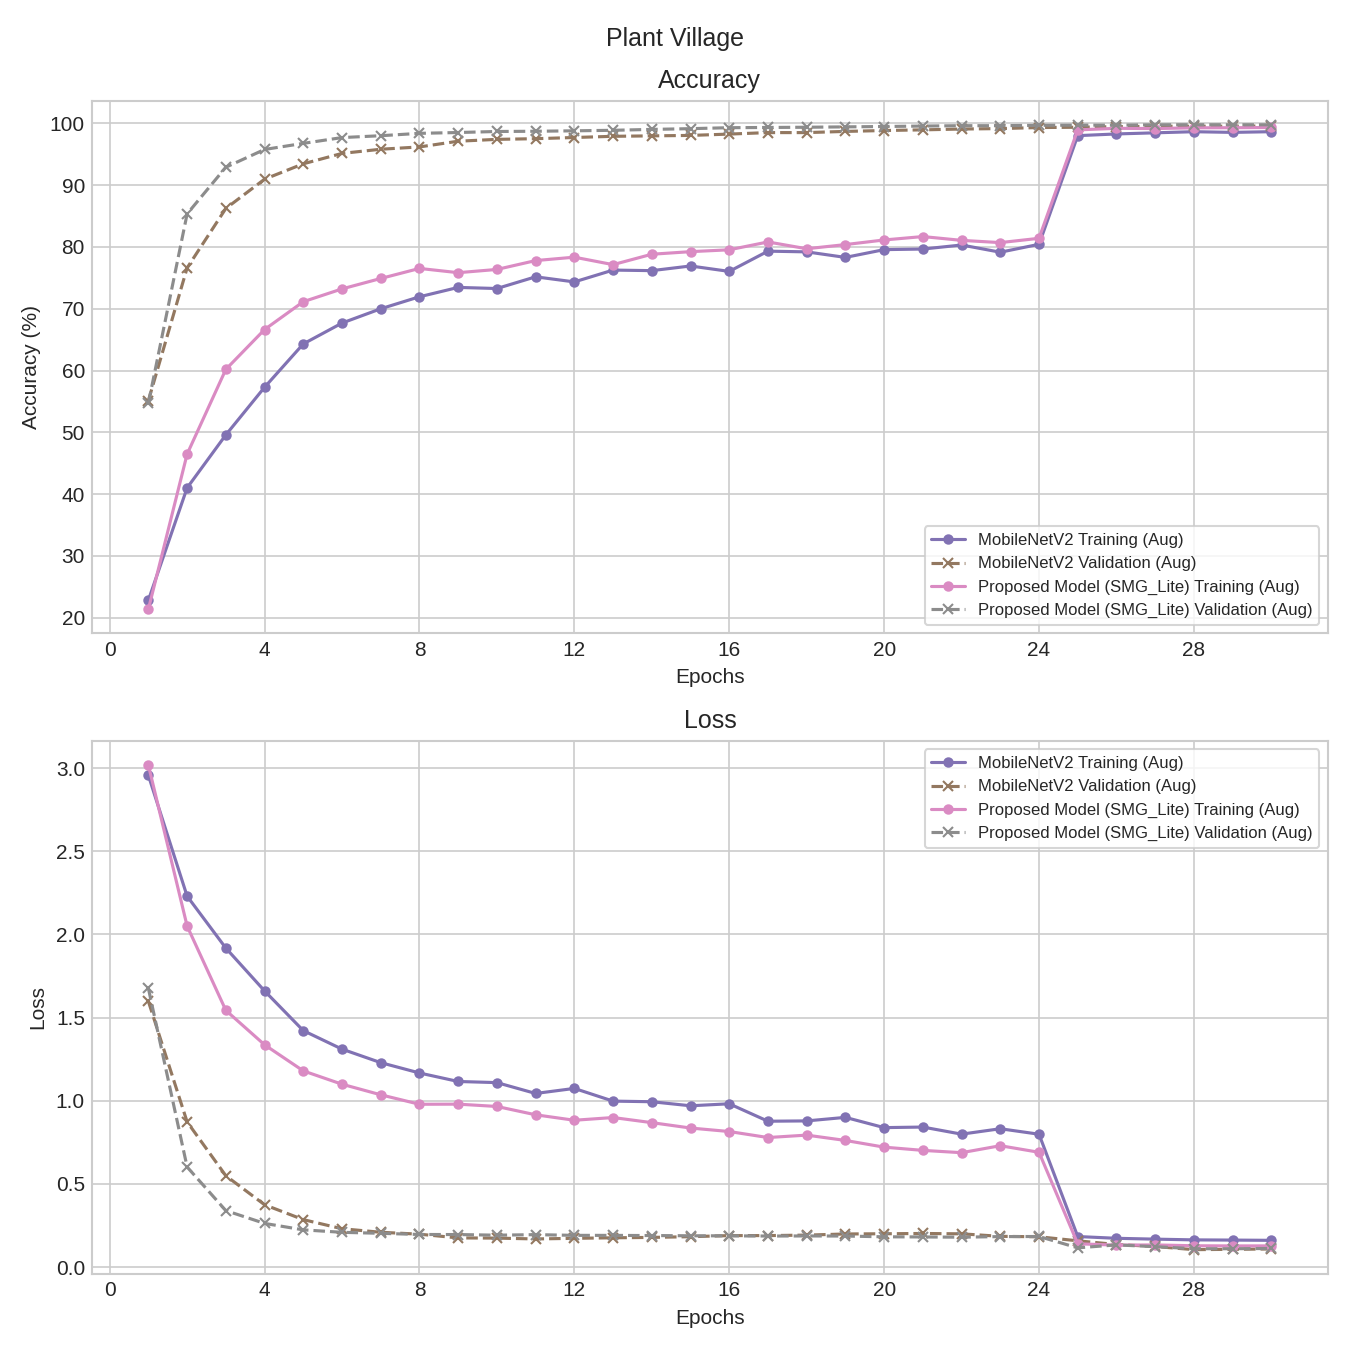

outputs/figures/curves_rice.png


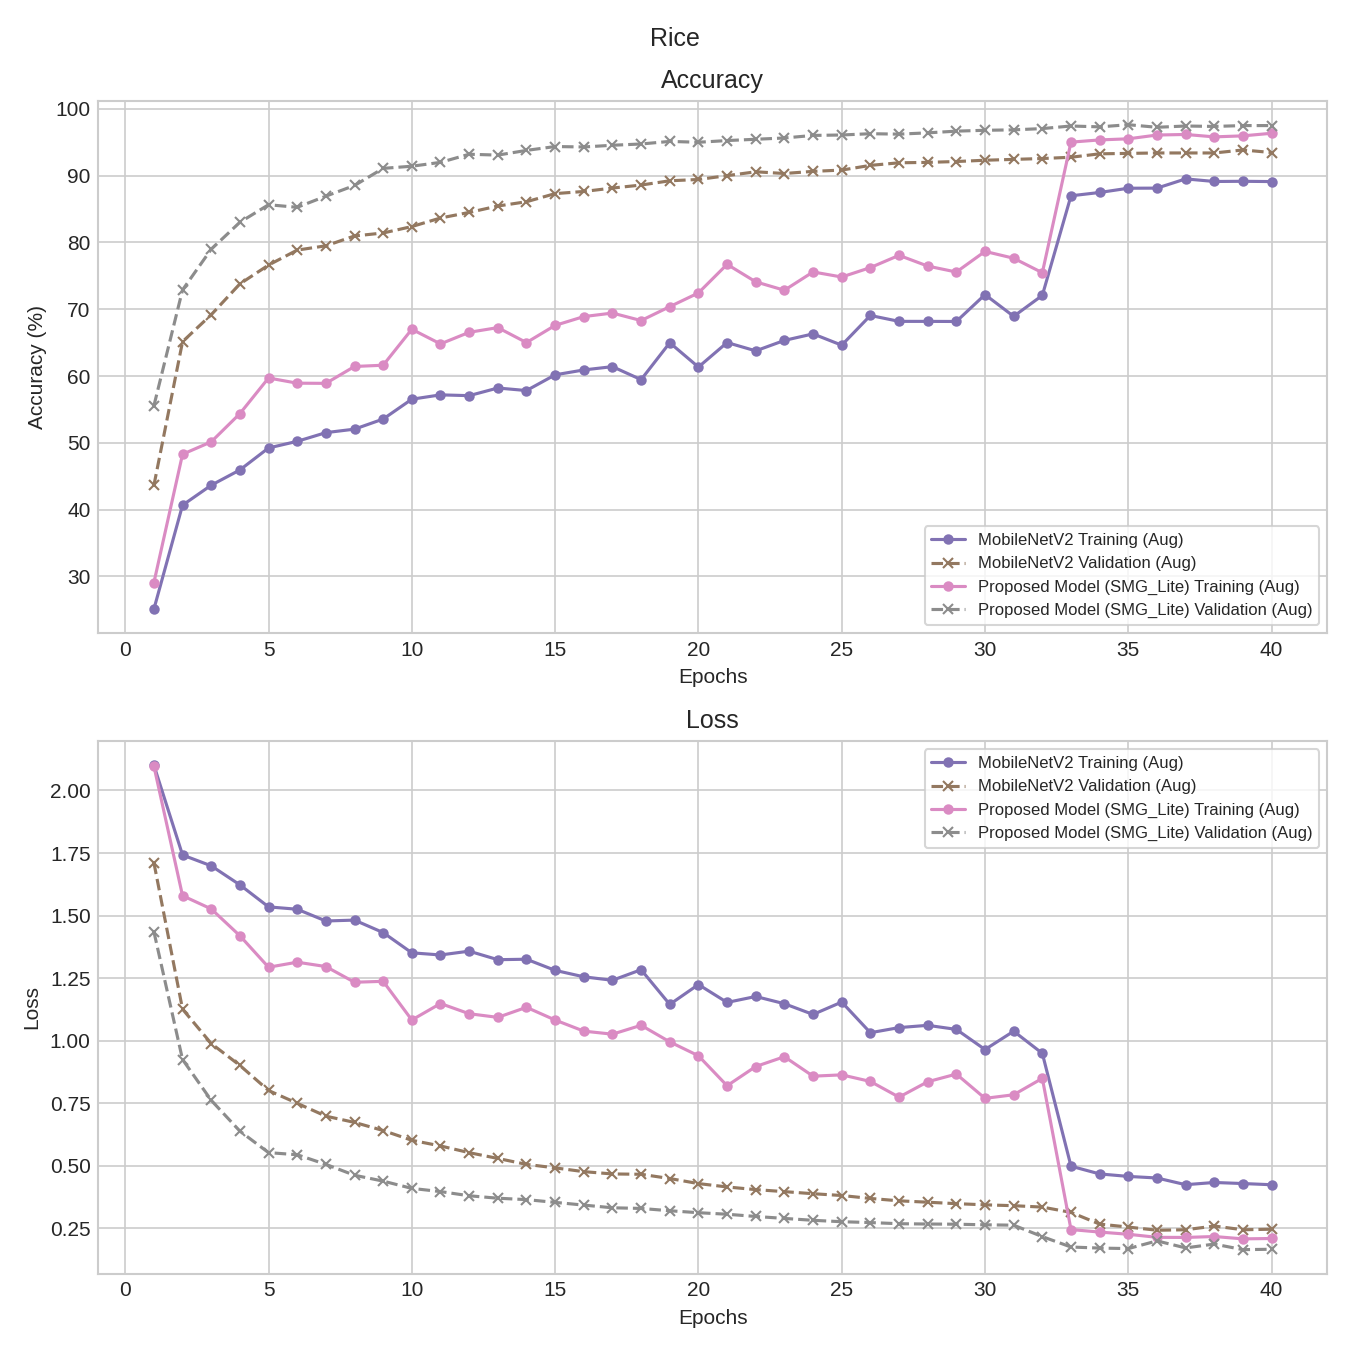

outputs/figures/curves_apple.png


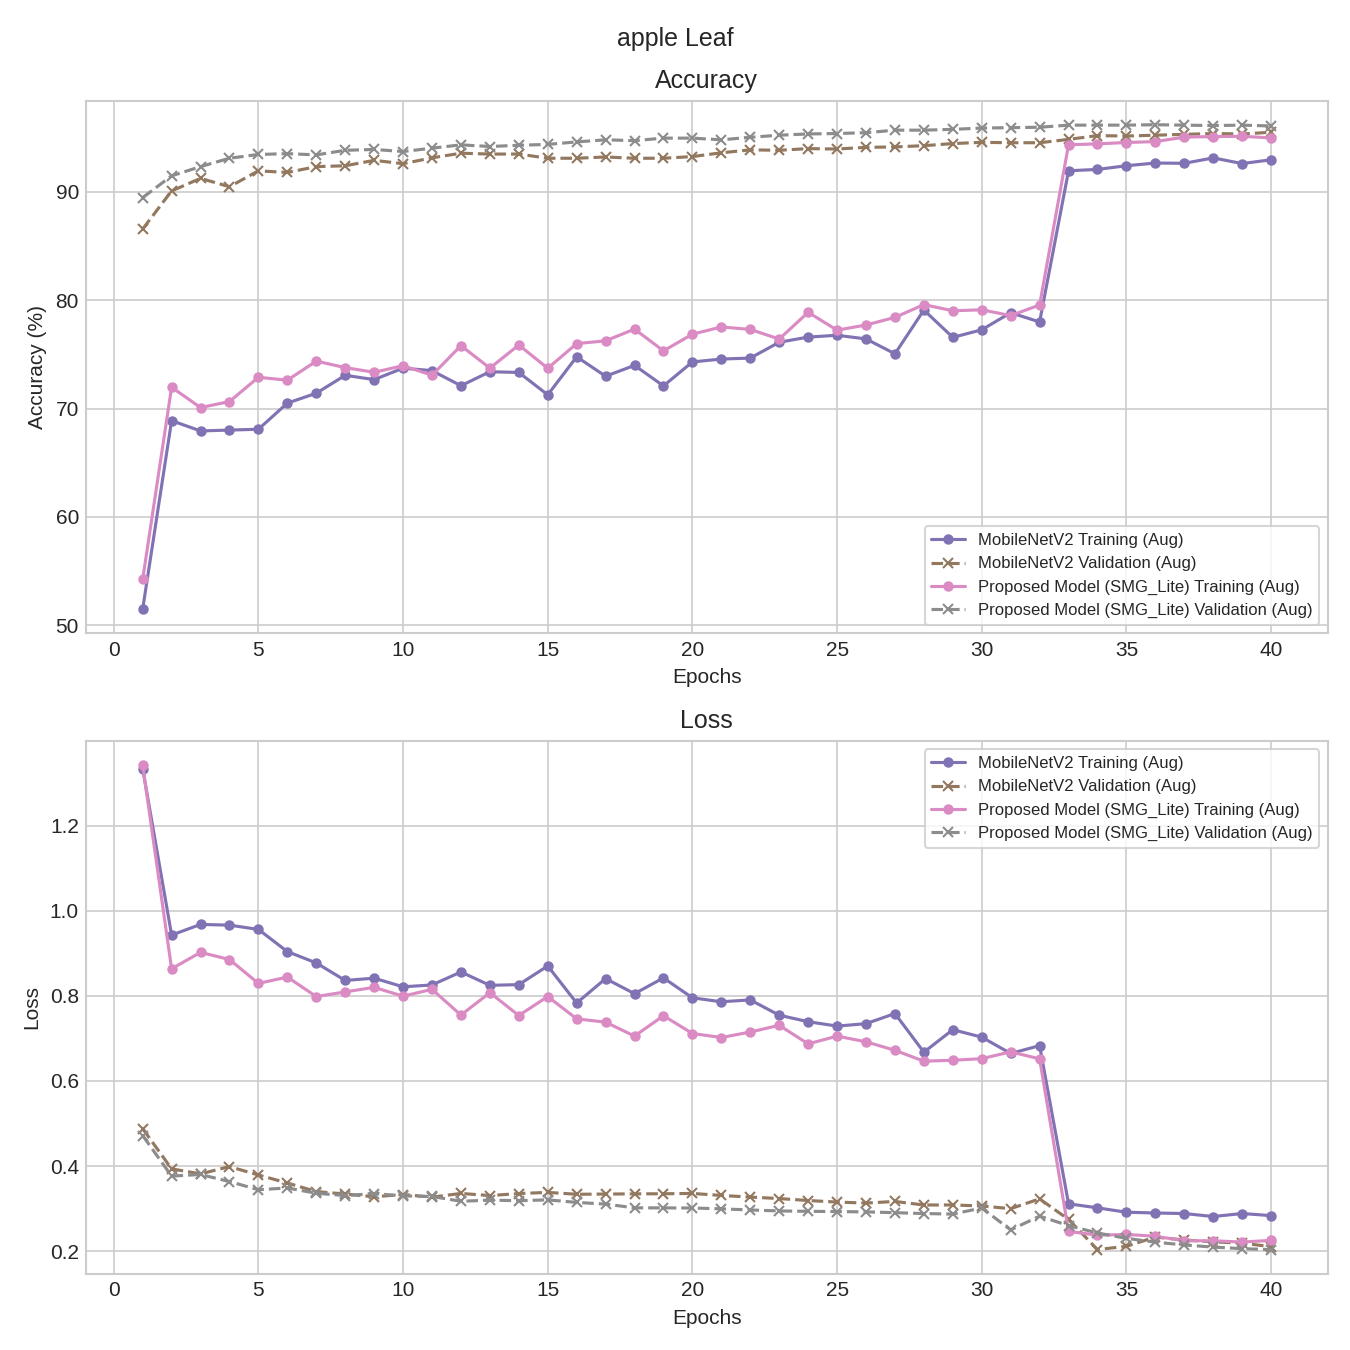

outputs/figures/curves_cassava.png


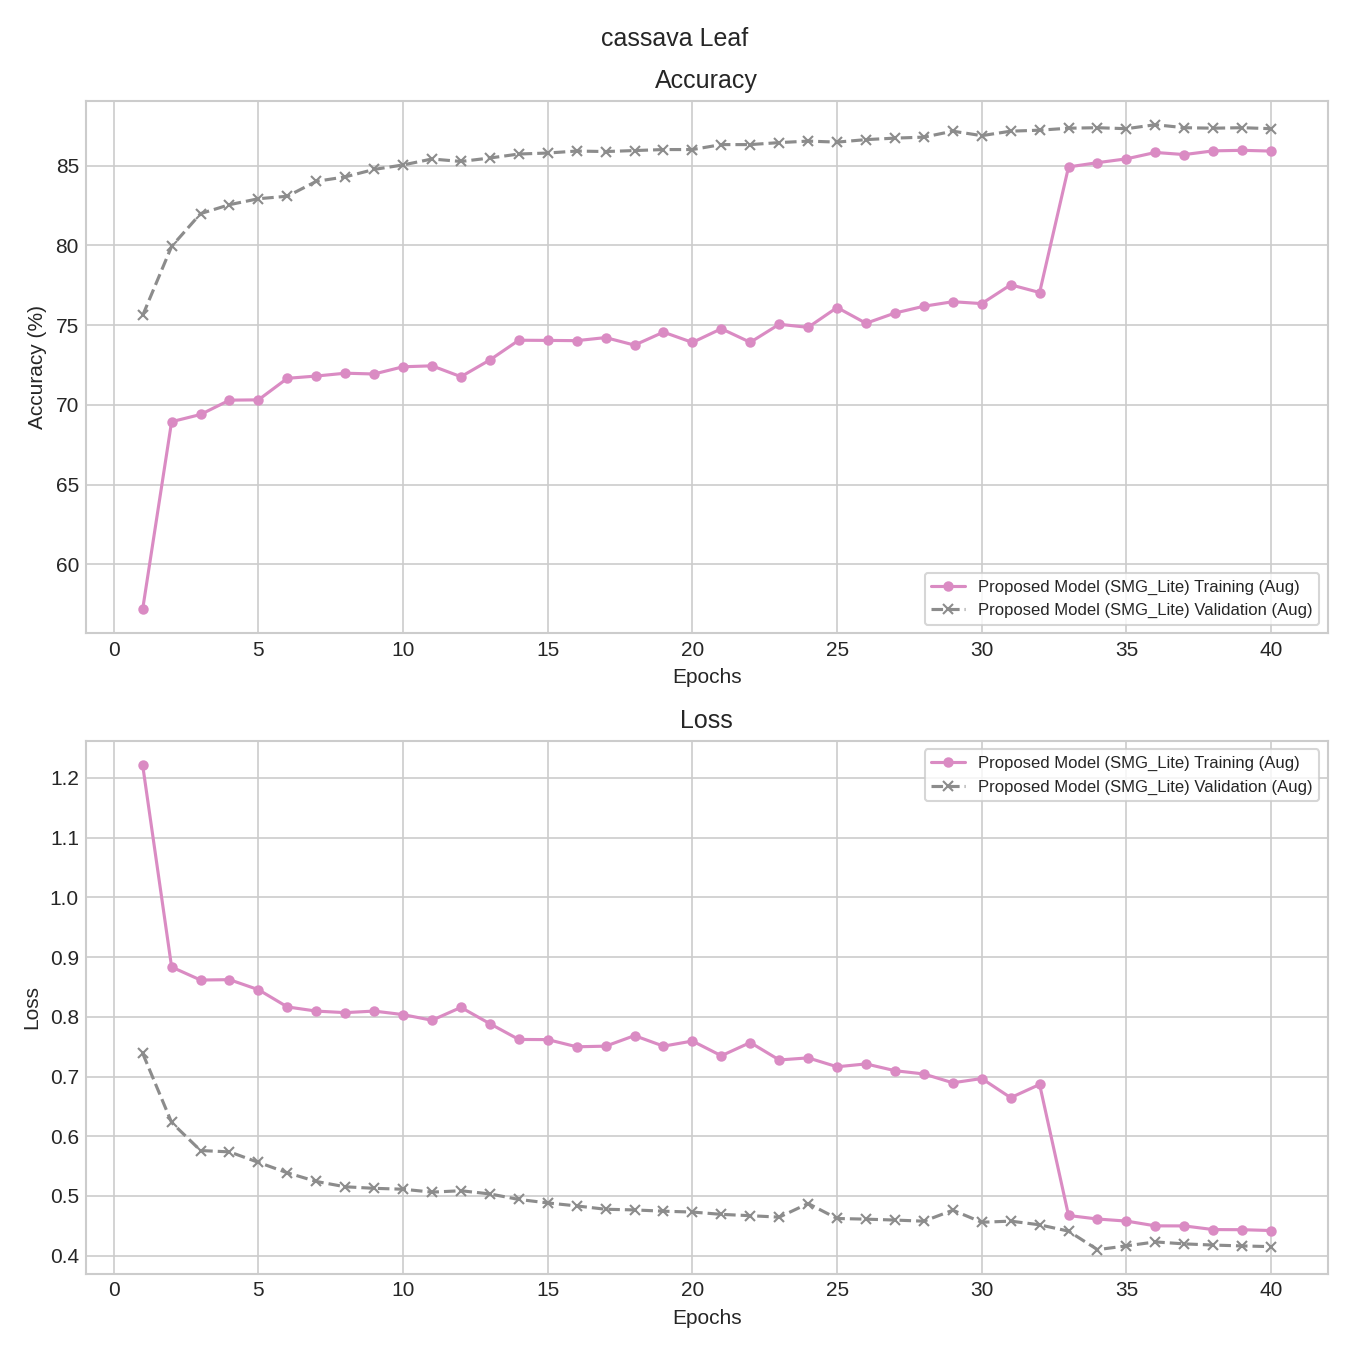

outputs/figures/confusion_plantvillage.png


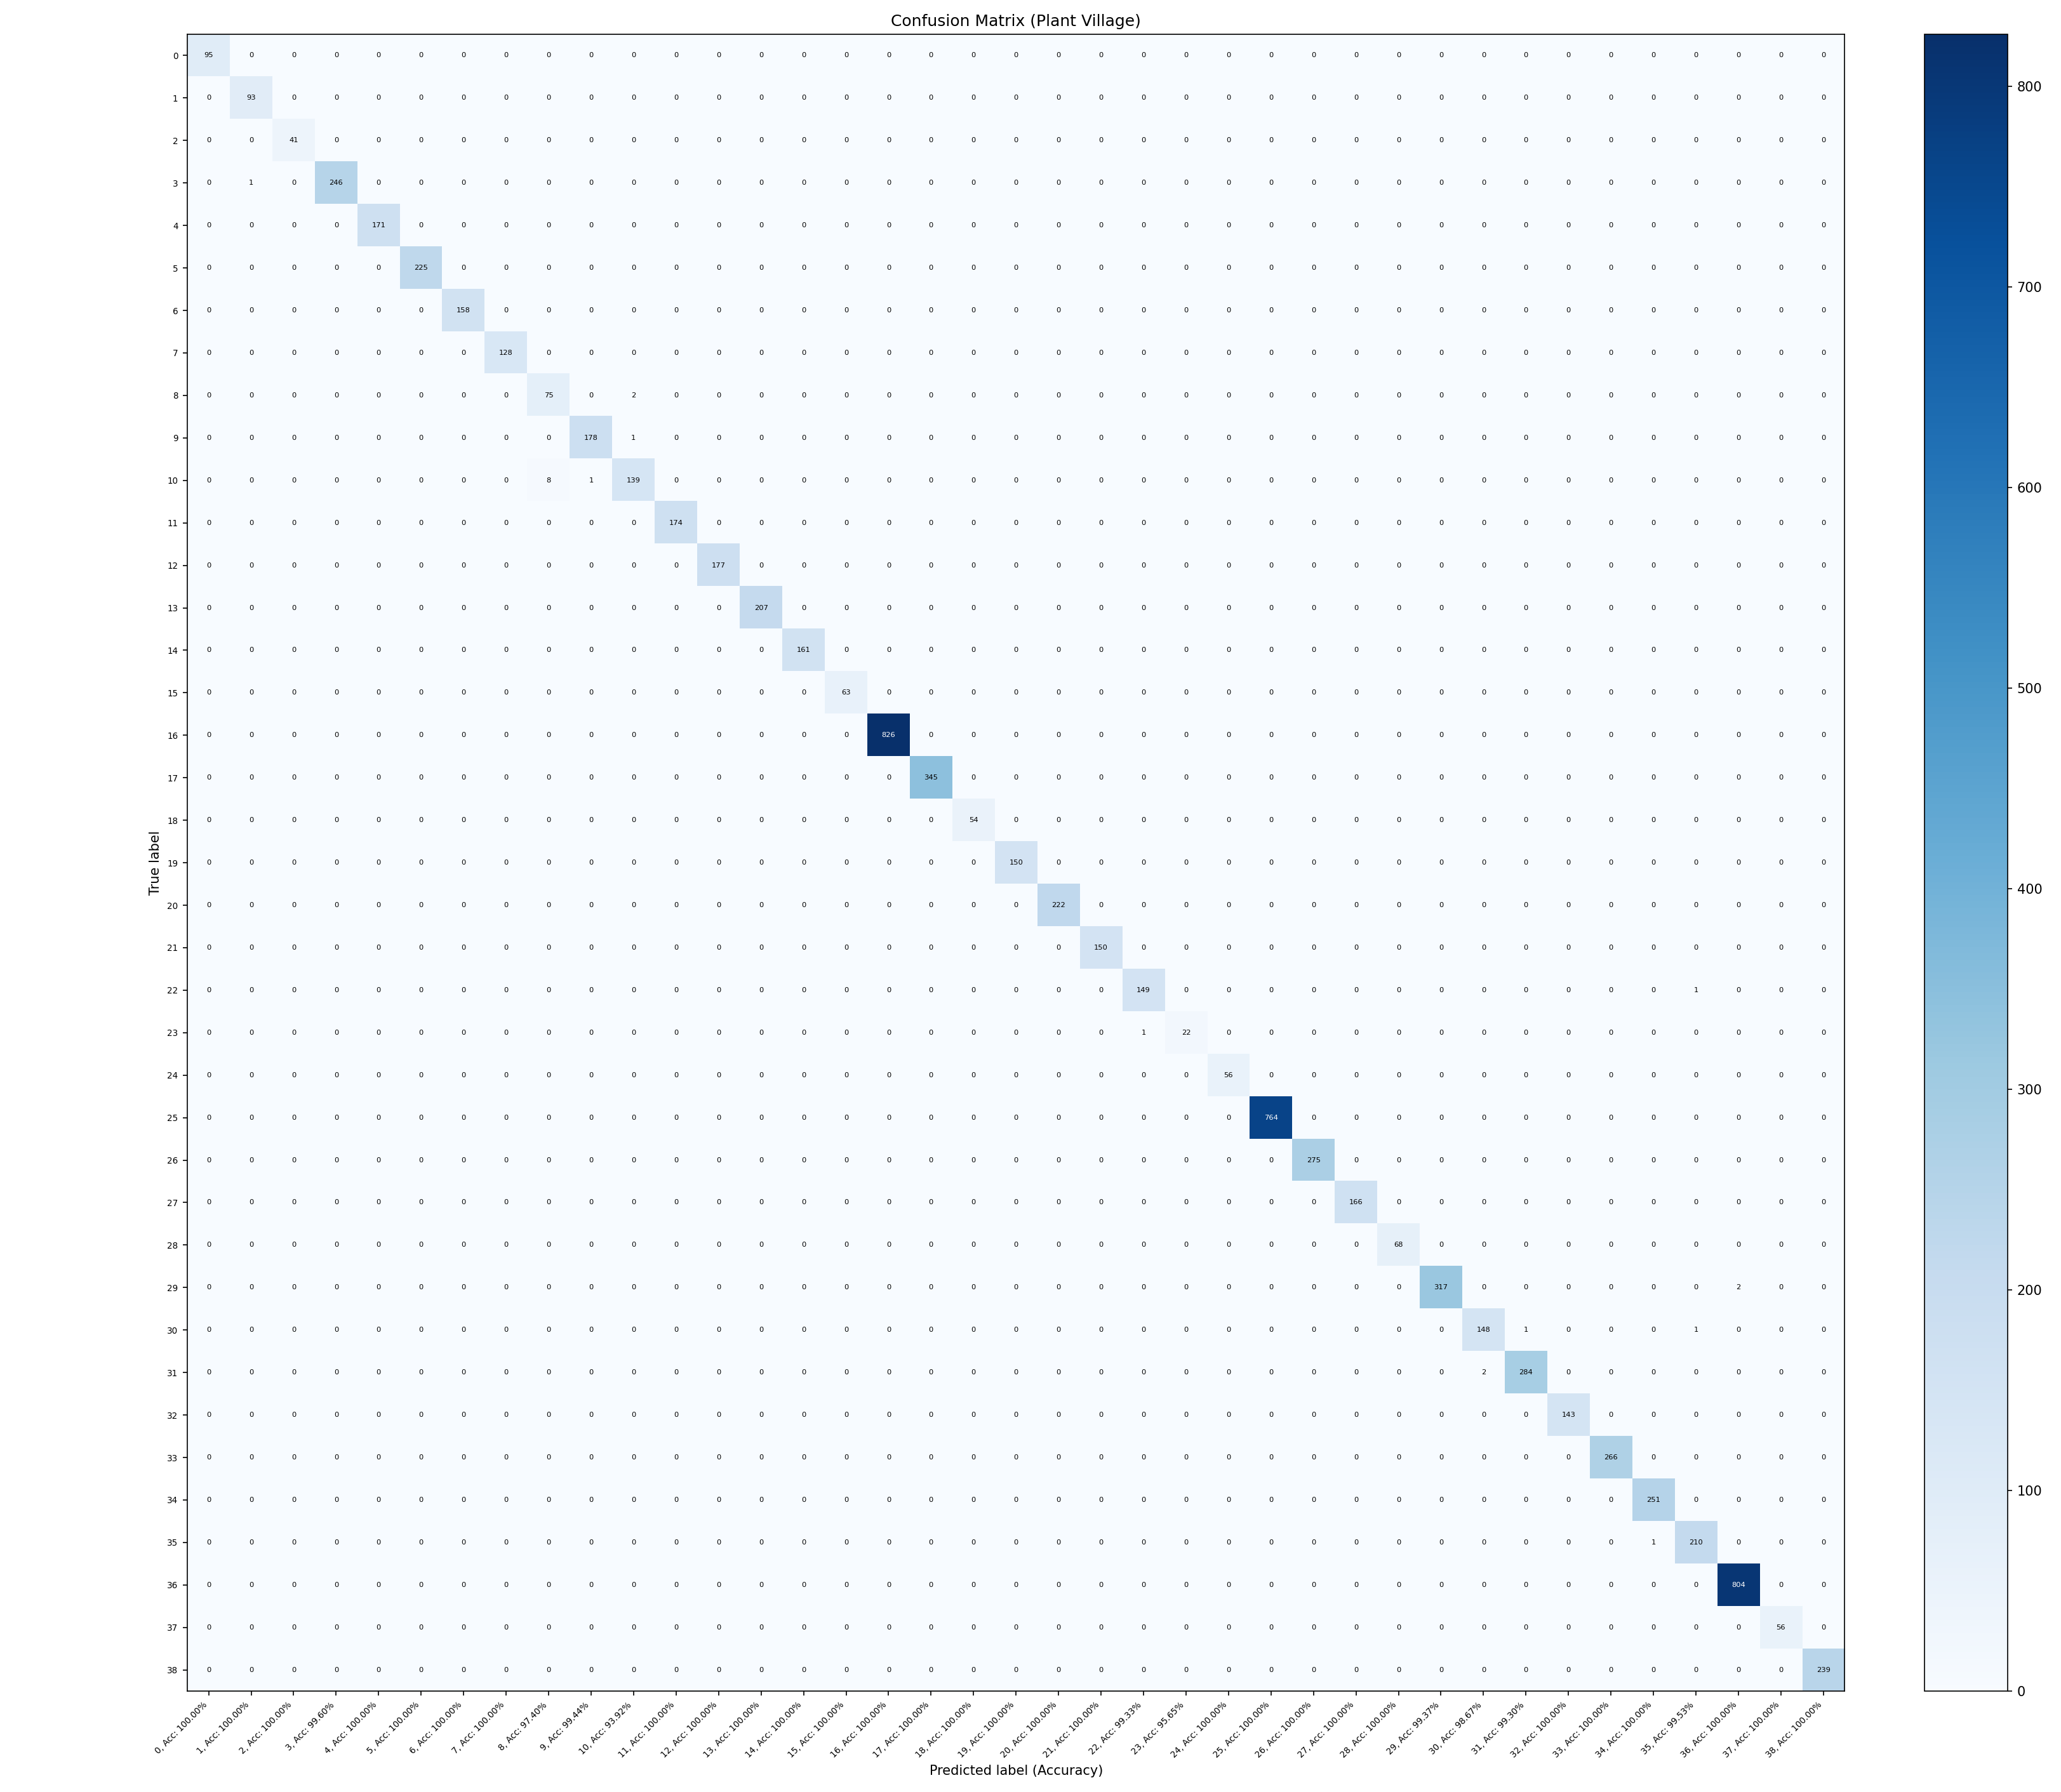

outputs/figures/confusion_rice.png


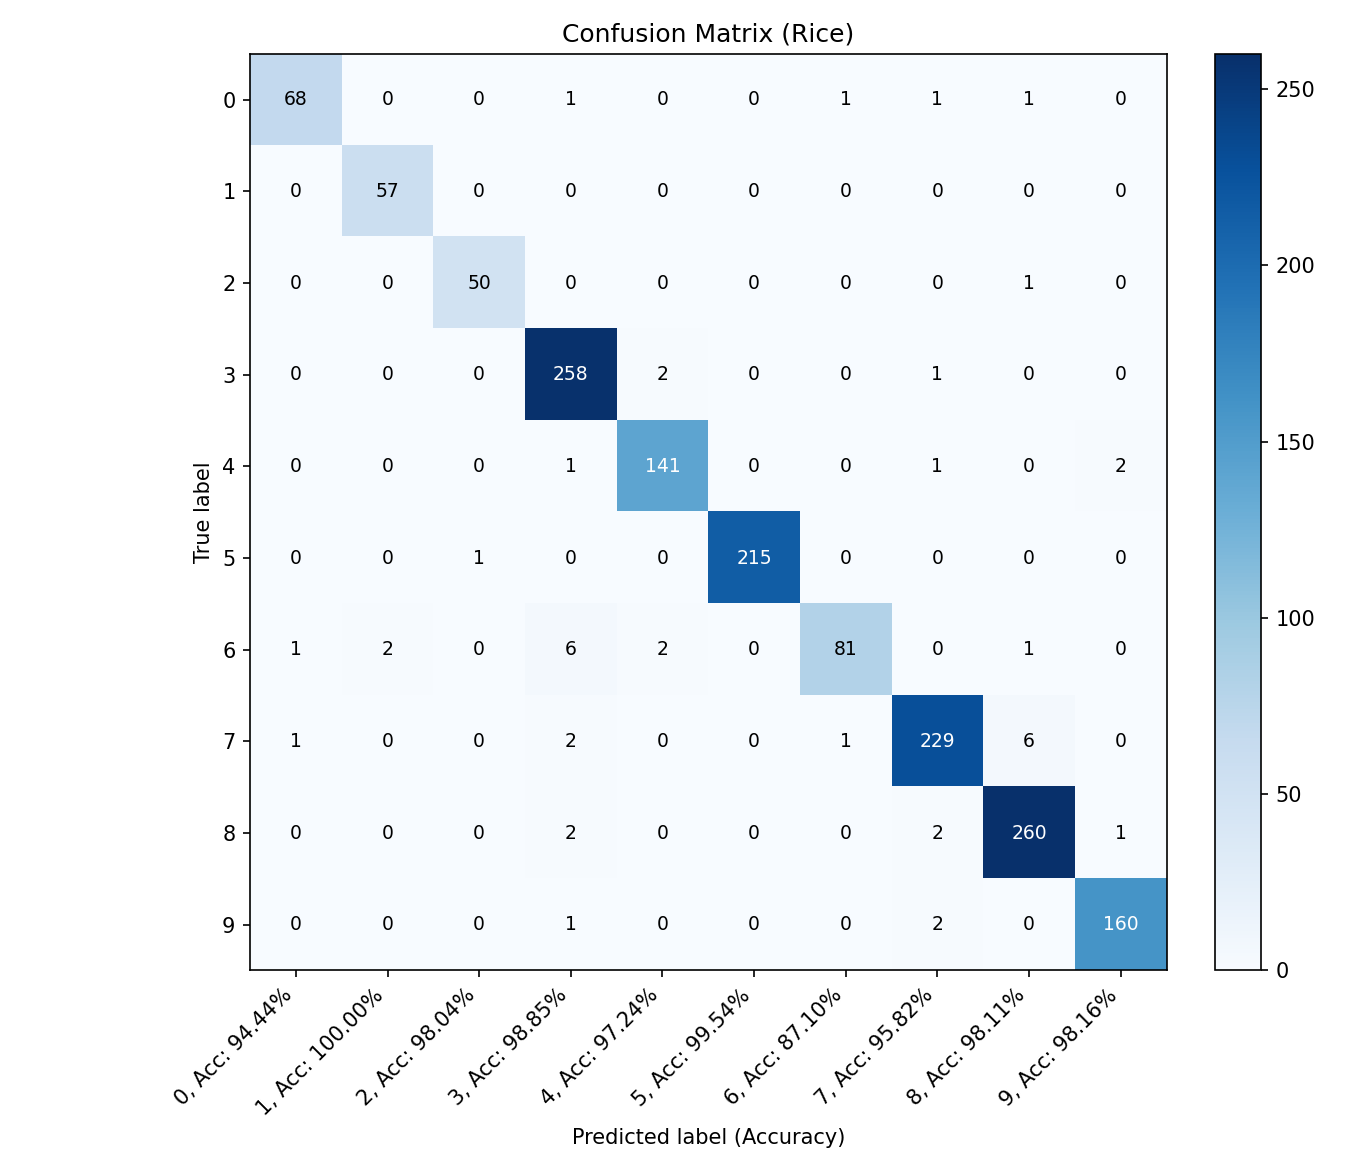

outputs/figures/confusion_apple.png


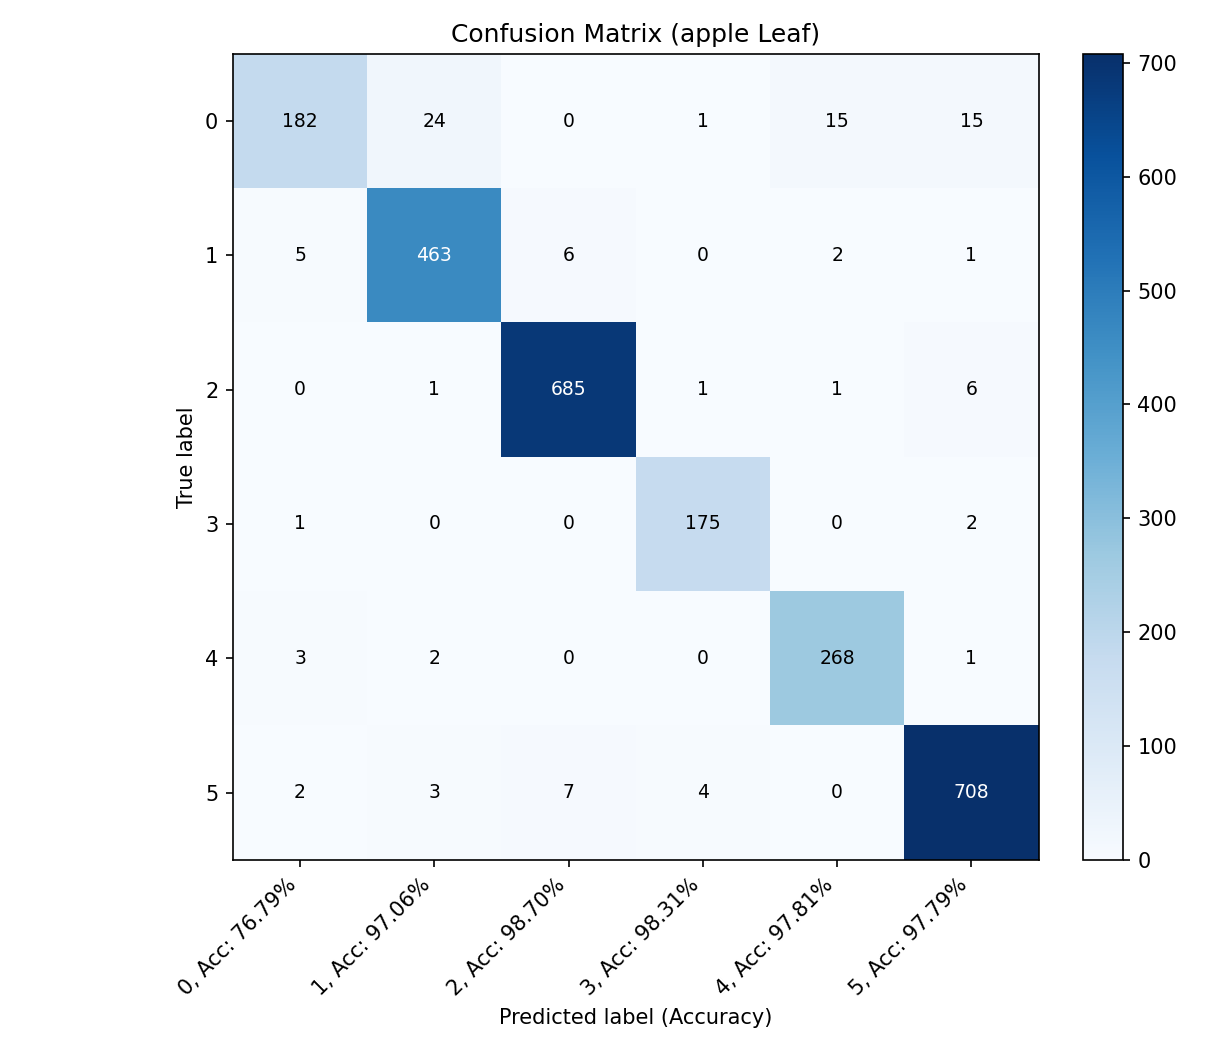

outputs/figures/confusion_cassava.png


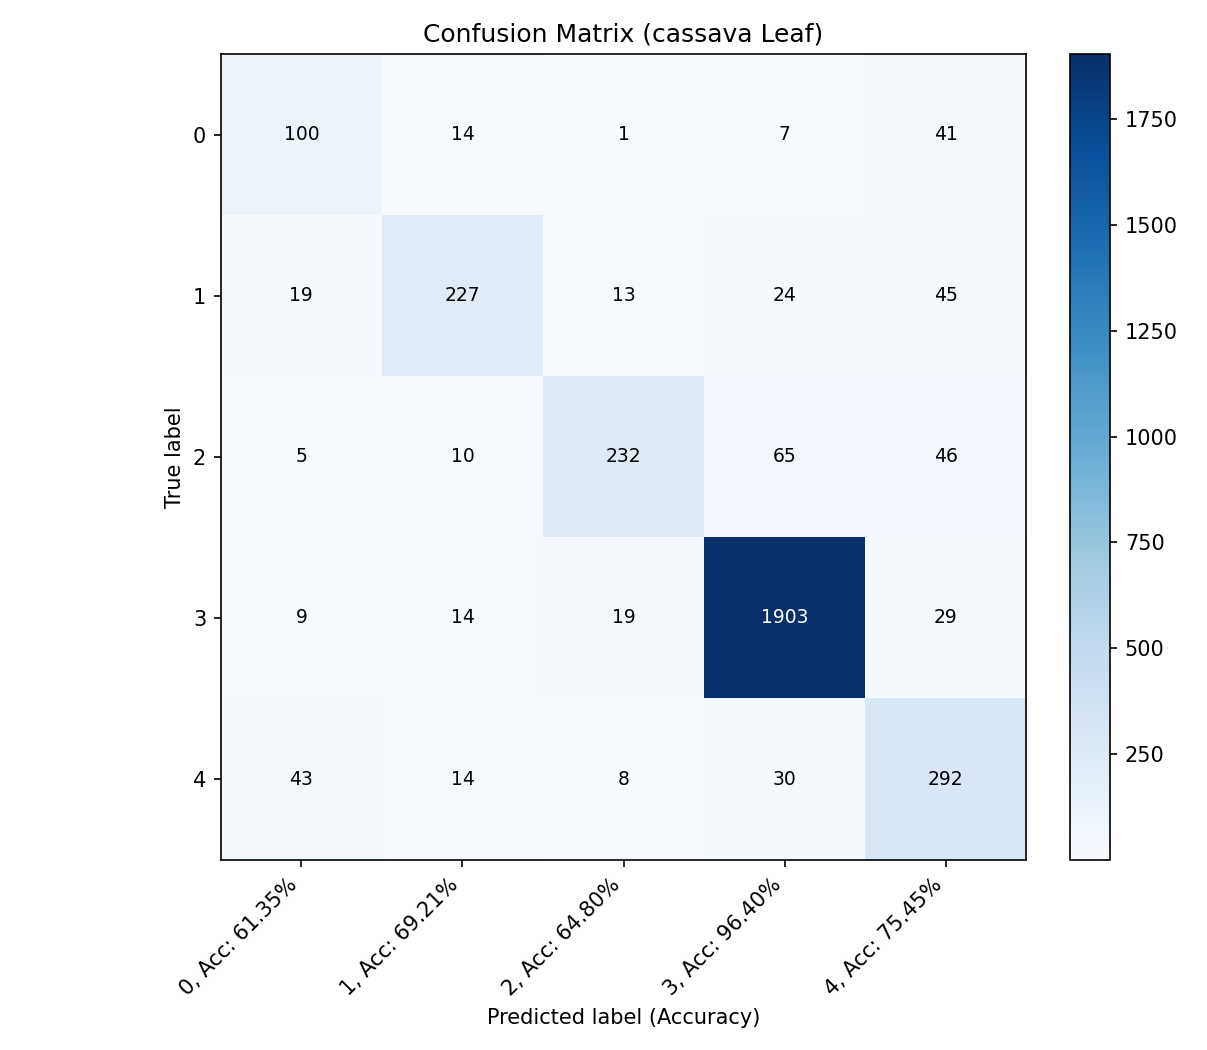

outputs/figures/roc_plantvillage.png


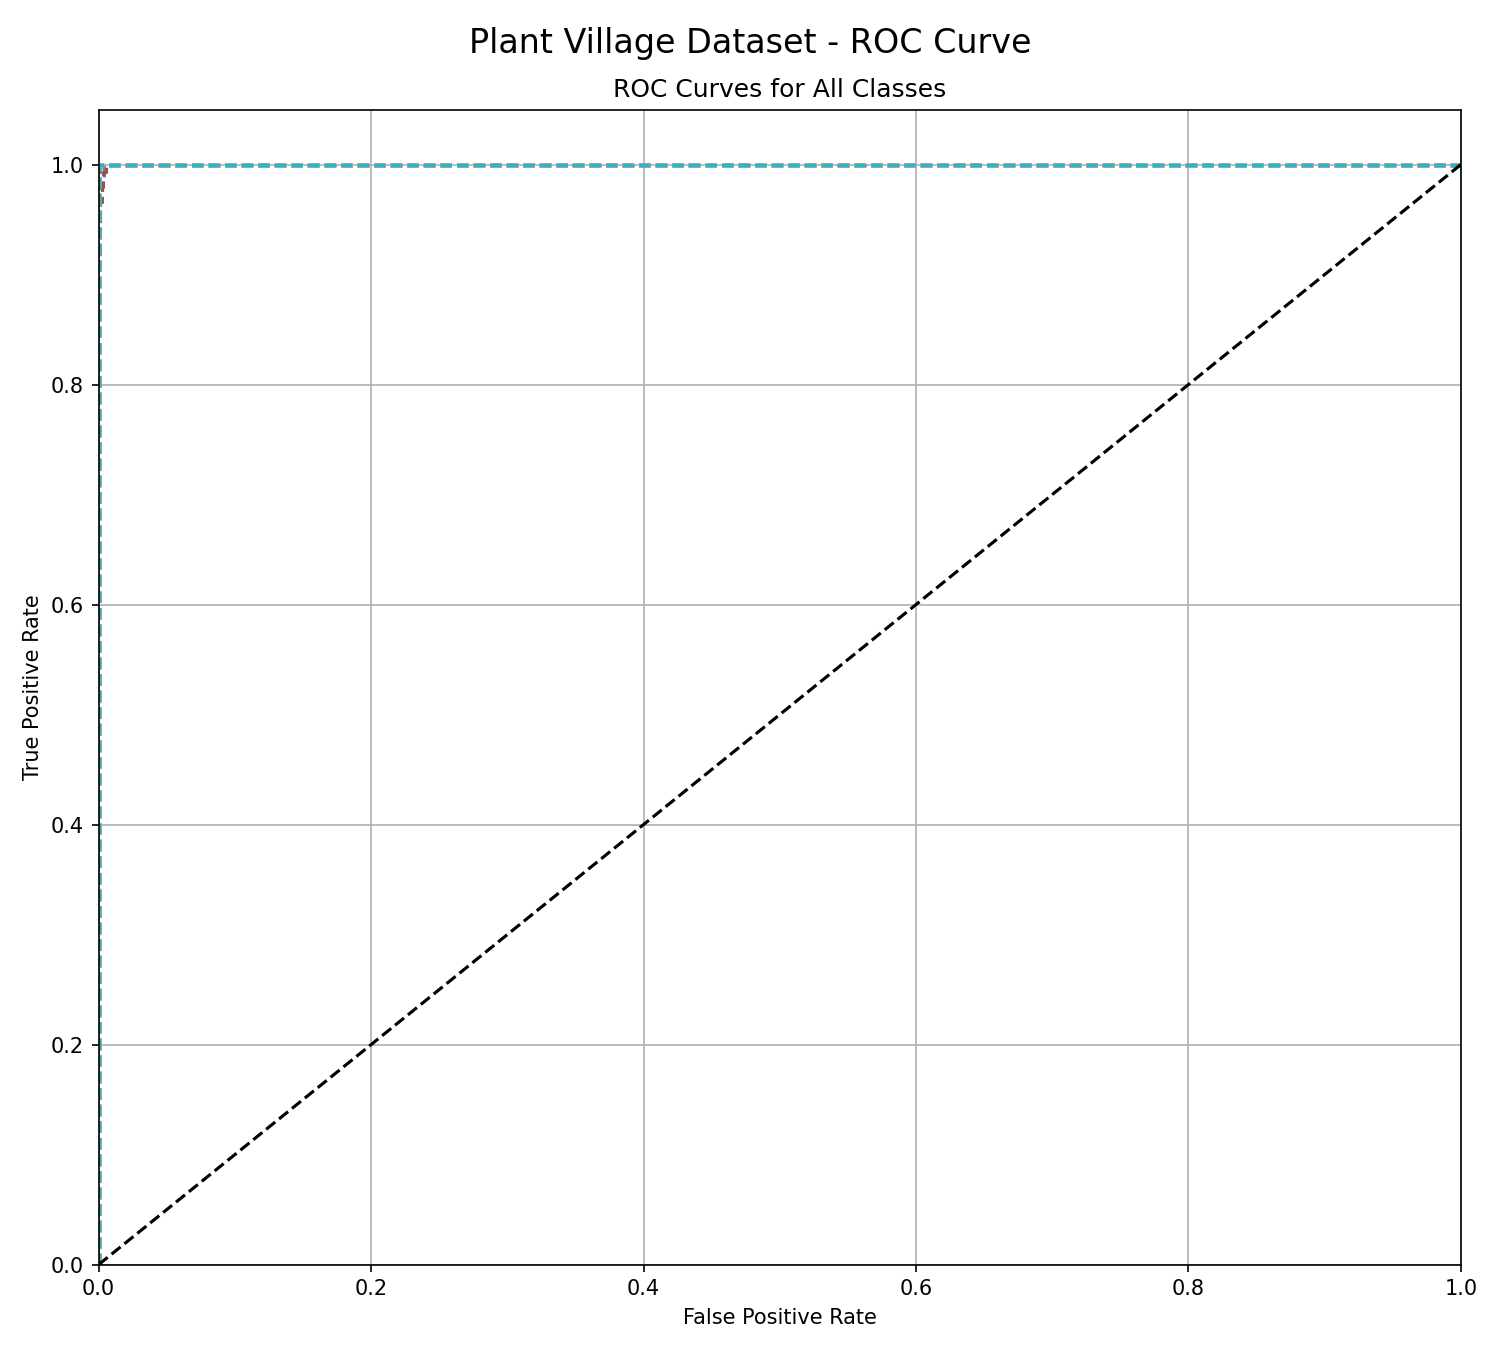

outputs/figures/roc_rice.png


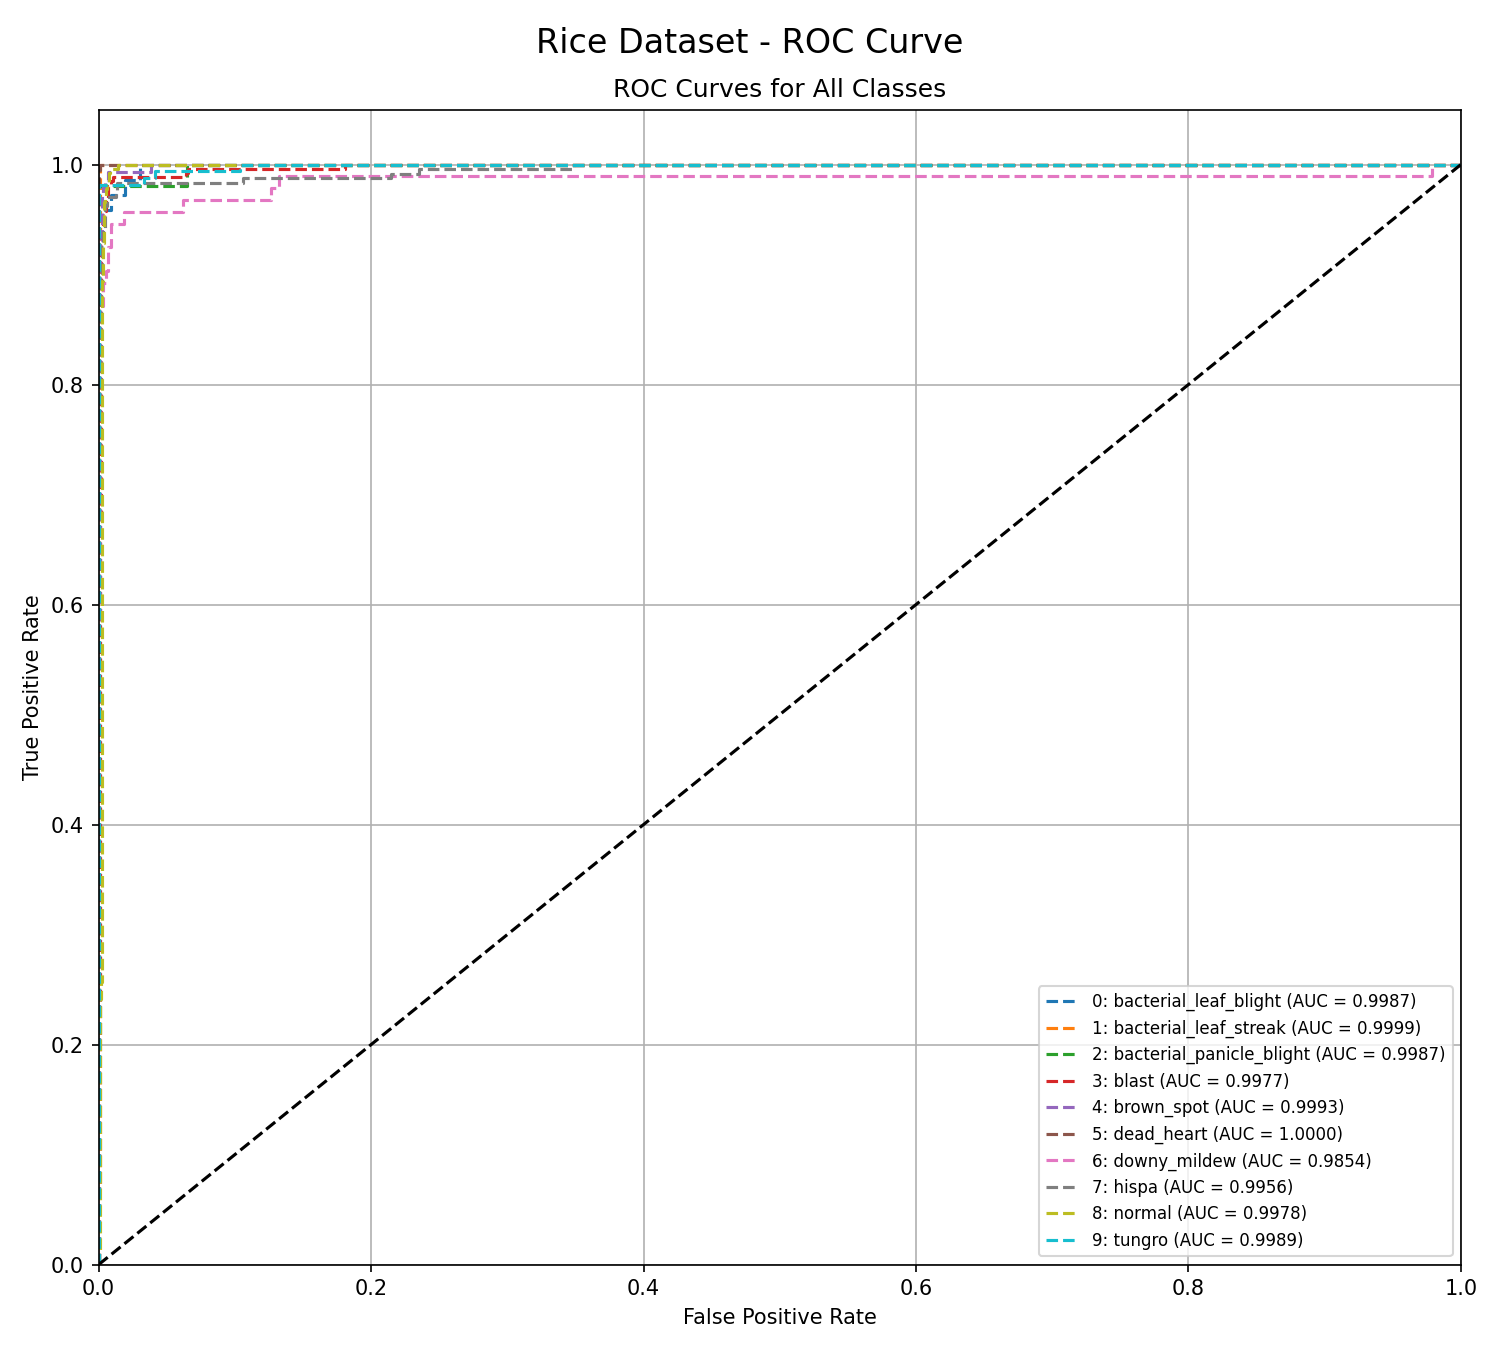

outputs/figures/roc_apple.png


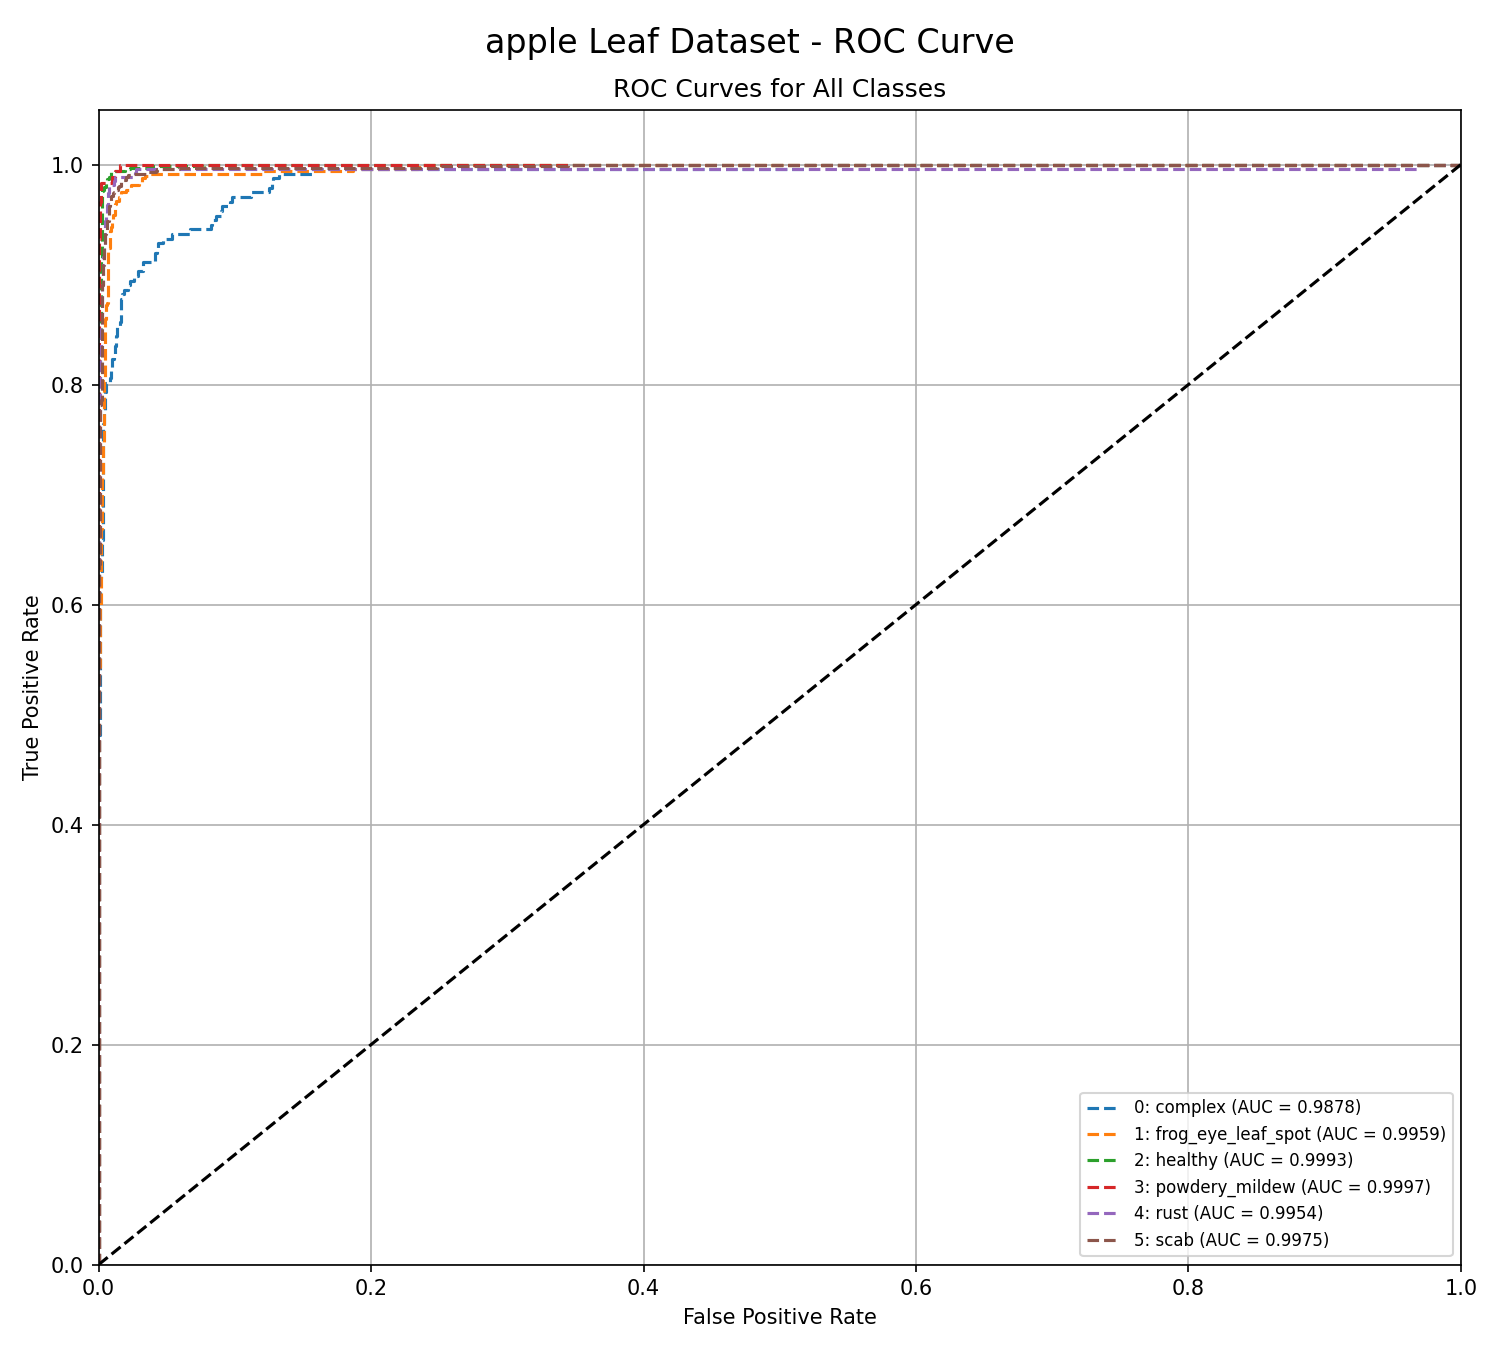

outputs/figures/roc_cassava.png


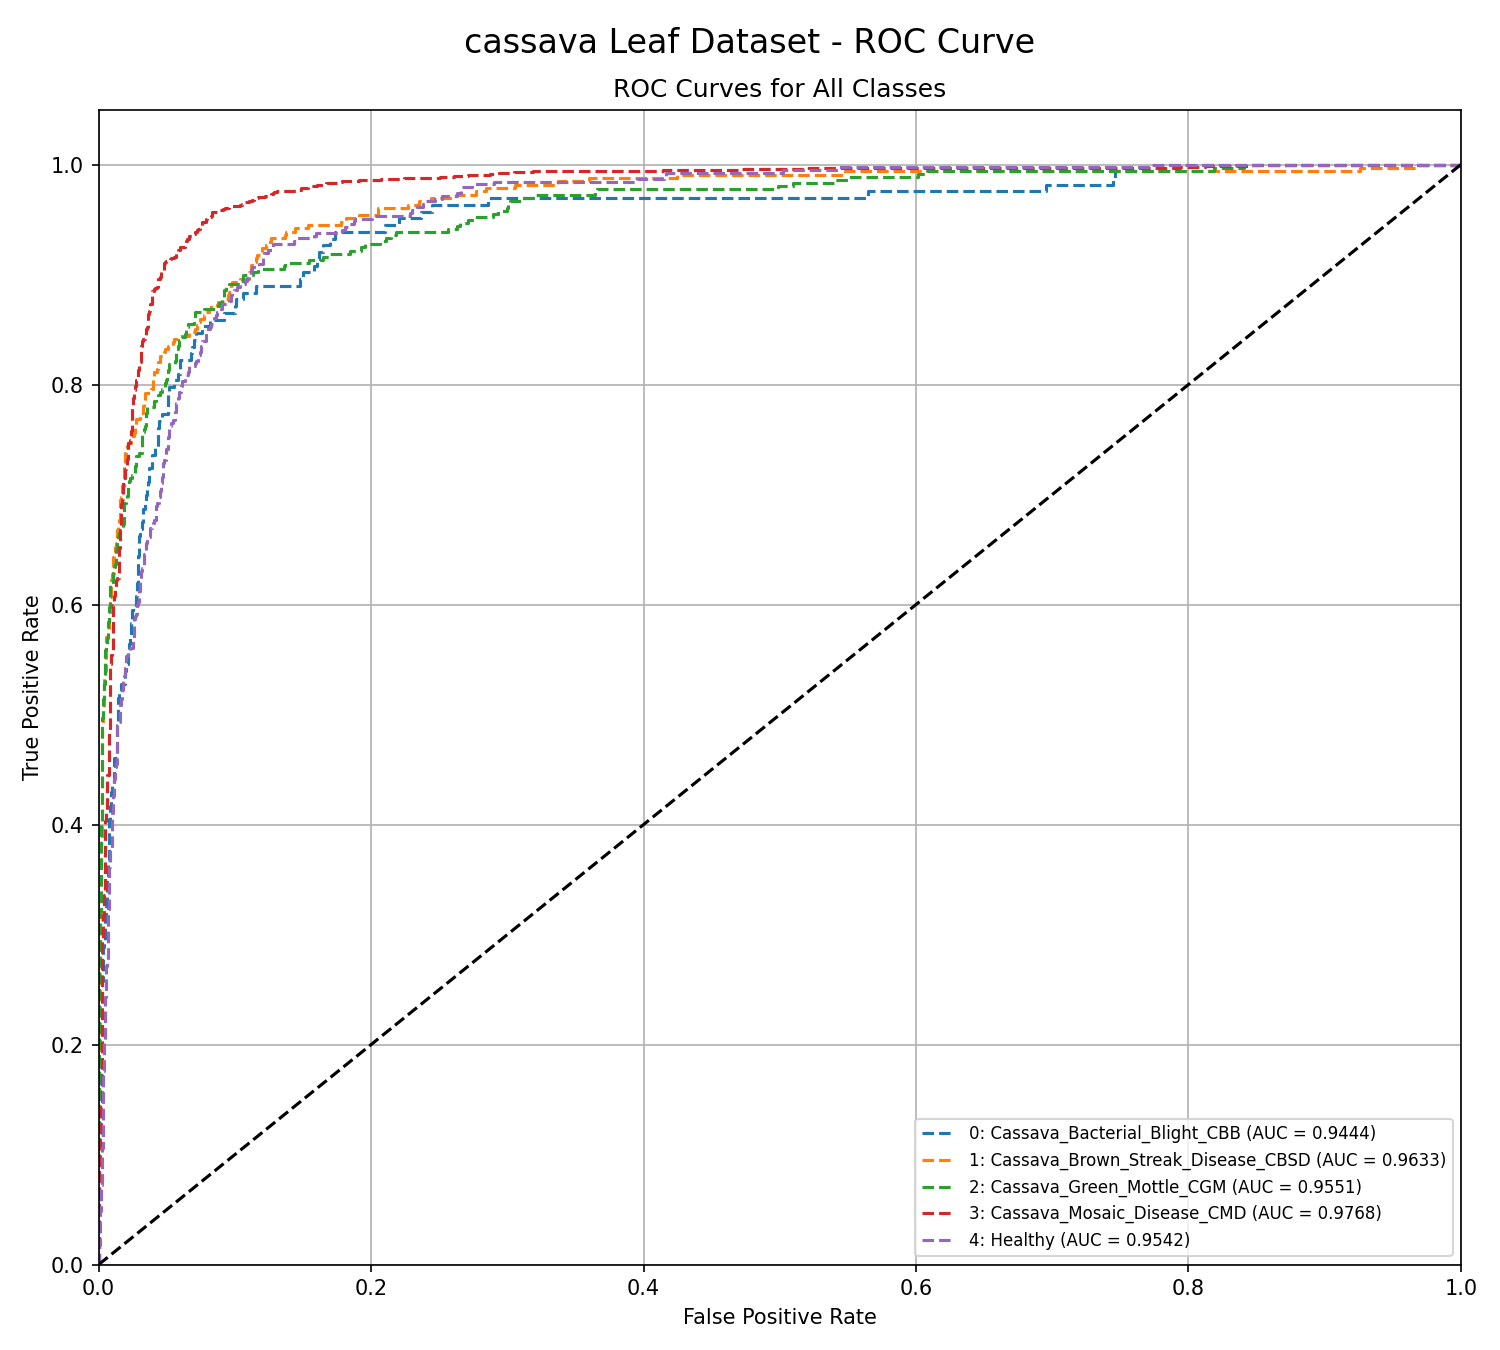

outputs/tables/ablation_rice.png


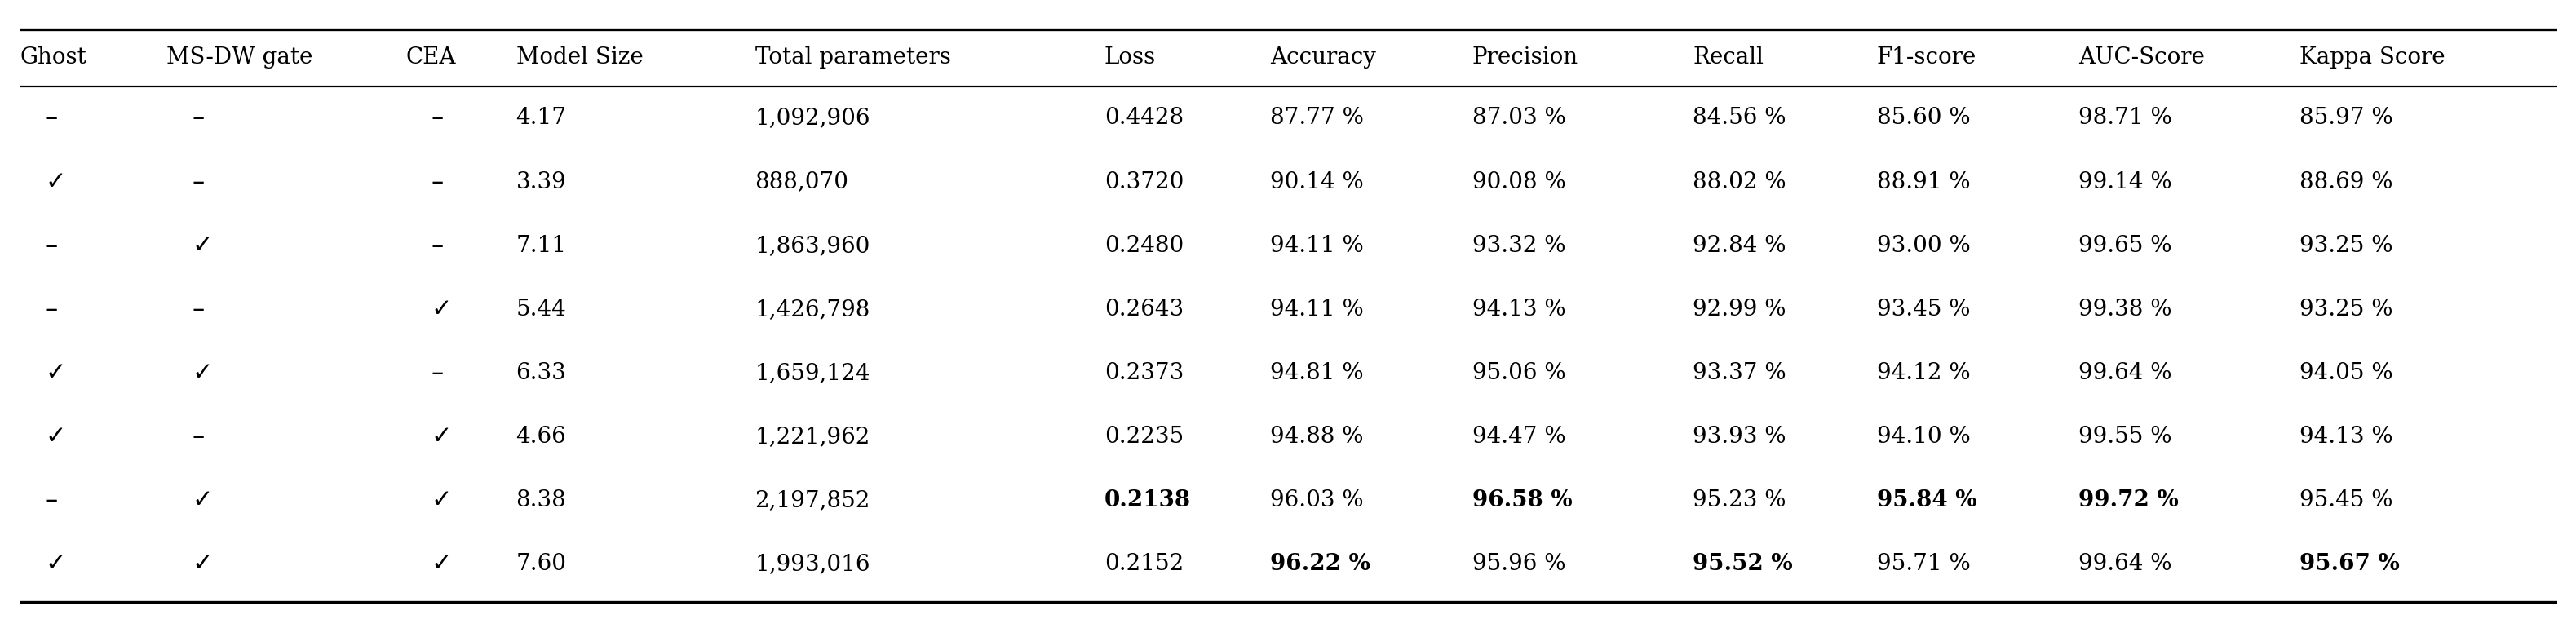

In [ ]:
# Show every figure in the same order as result_word.docx
from IPython.display import Image, display
out = lab.CFG["out_dir"]
for prefix in ["figures/metrics_lines", "figures/curves", "figures/confusion", "figures/roc", "tables/ablation"]:
    for ds in TABLE_ORDER + [d for d in DATASETS if d not in TABLE_ORDER]:
        f = os.path.join(out, f"{prefix}_{ds}.png")
        if os.path.exists(f):
            print(f); display(Image(f, width=900))

In [ ]:
exec(open(os.path.join(DRIVE_DIR if IN_COLAB else ".", "make_svg.py")).read())

21 SVG file(s) written:
   outputs/svg/tables/table_plantvillage.svg
   outputs/svg/figures/metrics_lines_plantvillage.svg
   outputs/svg/figures/curves_plantvillage.svg
   outputs/svg/figures/confusion_plantvillage.svg
   outputs/svg/figures/roc_plantvillage.svg
   outputs/svg/tables/table_rice.svg
   outputs/svg/figures/metrics_lines_rice.svg
   outputs/svg/figures/curves_rice.svg
   outputs/svg/figures/confusion_rice.svg
   outputs/svg/figures/roc_rice.svg
   outputs/svg/tables/table_apple.svg
   outputs/svg/figures/metrics_lines_apple.svg
   outputs/svg/figures/curves_apple.svg
   outputs/svg/figures/confusion_apple.svg
   outputs/svg/figures/roc_apple.svg
   outputs/svg/tables/table_cassava.svg
   outputs/svg/figures/metrics_lines_cassava.svg
   outputs/svg/figures/curves_cassava.svg
   outputs/svg/figures/confusion_cassava.svg
   outputs/svg/figures/roc_cassava.svg
   outputs/svg/tables/ablation_rice.svg

all SVG in one zip -> outputs/svg_images.zip
also saved in       -> /conten